In [2]:
import pickle
import yaml
import anndata as ad
import matplotlib as mpl
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import scvelo
import seaborn as sns
import torch
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
import math

from scipy import stats
from scipy.spatial import distance
from sklearn import ensemble, linear_model, preprocessing
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline
from tqdm import tqdm
from sklearn import preprocessing
from sklearn import linear_model
from sklearn import ensemble
from sklearn.model_selection import cross_val_score, cross_validate
from sklearn.pipeline import Pipeline


from velotest.hypothesis_testing import run_hypothesis_test_on
from velotest.neighbors import find_neighbors, find_neighbors_in_direction_of_velocity
from velotest.plotting import arrow_plot, compute_angle_on_gridplot_between, plot_best_possible_velocities_statistic, plot_uniformity_histogram

In [3]:
def calculateBound(adata, k=None, neighbors=True): 
    if neighbors is True:
        nn_indices_optimal = find_neighbors(torch.tensor(adata.layers['Ms']), k_neighbors=200)

    mins = torch.tensor([-2.]*len(adata))
    maxs = torch.tensor([-2.]*len(adata))
    for i in tqdm(range(len(adata))):
        cos = torch.nn.CosineSimilarity(dim=1, eps=1e-6)
        if neighbors is True:
            expression_all = torch.tensor(adata.layers['Ms'][nn_indices_optimal[i]][:,adata.var.velocity_genes])
        else:
            expression_all = torch.tensor(adata.layers['Ms'][:,adata.var.velocity_genes])
        expression_cell = torch.tensor(adata.layers['Ms'][i,adata.var.velocity_genes]).unsqueeze(0)
        velocity = torch.tensor(adata.layers['velocity'][i,adata.var.velocity_genes]).unsqueeze(0)
        cosines = cos(expression_all - expression_cell, velocity)
        cosines = torch.cat([cosines[:i], cosines[i+1:]])
        if k is None:
            mins[i] = torch.min(cosines)
            maxs[i] = torch.max(cosines)
        else:
            mins[i] = torch.mean(torch.topk(cosines, largest=False, k=k).values)
            maxs[i] = torch.mean(torch.topk(cosines, largest=True, k=k).values)

    return maxs

def bestVelocityEmbedded(adata, basis, clusters, cluster_colors):
    Z_expr = f"X_{basis}"
    Z_velocity_vector = f"velocity_{basis}"
    scvelo_velocities = adata.obsm[f"velocity_{basis}"]

    scvelo_lengths = np.linalg.norm(scvelo_velocities, axis=1)
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, basis=basis, number_neighbors_to_sample_from=200, null_distribution="velocities-explicit", cosine_empty_neighborhood=None, correction="bonferroni", restrict_to_velocity_genes=True, exclusion_degree=10)
    statistics = debug_dict['statistics']
    # Added this line, because some cells still had a statistice but in regard to the p_value they were empty neighborhoods.
    for i, p_val in enumerate(uncorrected_p_values):
            if p_val == 2:
                statistics[i] = None
    non_empty_neighborhoods_indices = np.where(uncorrected_p_values != 2)[0]

    # Calculate emmbeding test optimal statistic
    best_possible_velocities = [statistic.get_max_value(offset=True)[0] for statistic in statistics if
                                    statistic is not None]
    best_velocity_range_mean = []
    for range_best in best_possible_velocities:
        best_velocity_range_mean.append((range_best[0] + range_best[1]) / 2)
    best_velocity_range_mean = np.array(best_velocity_range_mean)
    best_velocities = np.stack([np.cos(best_velocity_range_mean), np.sin(best_velocity_range_mean)], axis=-1)
    best_velocities *= scvelo_lengths[non_empty_neighborhoods_indices, None]
    
    adata_best = adata.copy()
    adata_best.obsm[Z_velocity_vector] = np.zeros((adata.shape[0], 2))
    adata_best.obsm[Z_velocity_vector][non_empty_neighborhoods_indices] = best_velocities
    length_velocity = np.linalg.norm(adata_best.obsm[Z_velocity_vector], axis=1, keepdims=True)
    length_velocity[length_velocity == 0] = 1  # Prevent division by zero for

    adata_plotting = ad.AnnData(adata_best.X, obs=adata_best.obs.copy())
    adata_plotting.obsm[Z_expr] = adata_best.obsm[Z_expr]
    adata_plotting.obsm[Z_velocity_vector] = adata_best.obsm[Z_velocity_vector]/length_velocity
    adata_plotting.layers['velocity'] = adata_best.layers['velocity']
    adata_plotting.uns[cluster_colors] = adata_best.uns[cluster_colors]

    return adata_plotting

##########################################
##### NEW FUNCTION FOR THIS NOTEBOOK #####
##########################################

def add_non_nan_features(matrix, names, final_matrix, final_features):
    if sp.issparse(matrix):
        if np.isnan(matrix.data).any():
            matrix = matrix.toarray() # Convert to dense for row/col filtering
        else:
            final_matrix.append(matrix)
            final_features.extend(names)
            return final_matrix, final_features

    valid_cols_mask = ~np.isnan(matrix).any(axis=0)
    
    if valid_cols_mask.any(): # If at least one column is valid
        # Keep only valid columns
        final_matrix.append(matrix[:, valid_cols_mask])
        # Keep only names where the mask is True
        filtered_names = [name for i, name in enumerate(names) if valid_cols_mask[i]]
        final_features.extend(filtered_names)

    return final_matrix, final_features

def prepare_feature_matrix(adata_copy, cluster, basis):
    ### Restack the anndataobject for learning
    X_genes = adata_copy.X
    X_spliced = adata_copy.layers['spliced']
    X_unspliced = adata_copy.layers['unspliced'] 

    ### Use more than gene coutns
    # Velocity
    X_velocity_full = adata_copy.layers['velocity']
    valid_genes_mask = ~np.isnan(X_velocity_full).any(axis=0)
    vel_genes = adata_copy.var['highly_variable']
    # Splice/unpsliced totla and ratio
    total_spliced = np.asarray(X_spliced.sum(axis=1))
    total_unspliced = np.asarray(X_unspliced.sum(axis=1))
    ratio_su = total_spliced / (total_unspliced + 1e-9)
    # Other features saved in the object
    le = preprocessing.LabelEncoder()
    clusters = le.fit_transform(adata_copy.obs[cluster]).reshape(-1, 1)

    # Use the number of neighbors in the direction of velocity
    nn_indices = find_neighbors(torch.tensor(adata_copy.obsm['X_umap']), k_neighbors=200) # Find all eighbors in the 2D embedding 
    neighbors = find_neighbors_in_direction_of_velocity(torch.tensor(adata_copy.obsm['X_umap']), torch.tensor(adata_copy.obsm['X_umap']+adata_copy.obsm['velocity_umap']), nn_indices, 22.5) # Find all neighbor in the direction of velocity in the 2D embedding
    num_neighbors = np.array([len(neigh) for neigh in neighbors]).reshape(-1, 1)

    # Compute different velocities
    highD_velocity = np.linalg.norm(adata_copy.layers['velocity'][:,valid_genes_mask], axis=1).reshape(-1, 1)
    twoD_velocity = np.linalg.norm(adata_copy.obsm[f'velocity_{basis}'], axis=1).reshape(-1, 1)
    #variance = np.abs(adata_copy.layers['variance_velocity'])
    #var = np.asarray(variance.sum(axis=1)).reshape(-1, 1)
    confidence = adata_copy.obs['velocity_self_transition'].values.reshape(-1, 1)

    # Build matrix and check everyhting for nan values before stacking
    matrices = []
    final_feature = []
    genes = adata_copy.var_names

    matrices, final_feature = add_non_nan_features(X_genes, genes, matrices, final_feature)
    matrices, final_feature = add_non_nan_features(X_spliced, [f"spliced_{g}" for g in genes], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(X_unspliced, [f"unspliced_{g}" for g in genes], matrices, final_feature )
    matrices, final_feature = add_non_nan_features(X_velocity_full, [f"velocity_{g}" for g in genes], matrices, final_feature)

    matrices, final_feature = add_non_nan_features(total_spliced, ["total_spliced"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(total_unspliced, ["total_unspliced"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(ratio_su, ["ratio_su"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(clusters, ["clusters"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(num_neighbors, ["num_neighbors"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(highD_velocity, ["highD_velocity"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(twoD_velocity, ["twoD_velocity"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(confidence, ["confidence"], matrices, final_feature)

    X = sp.hstack(matrices)
    features = final_feature

    return X, features

def prepare_rim_matrix(adata_copy, cluster, basis):
    ### Restack the anndataobject for learning
    X_spliced = adata_copy.layers['spliced']
    X_unspliced = adata_copy.layers['unspliced'] 

    ### Use more than gene coutns
    # Velocity
    X_velocity_full = adata_copy.layers['velocity']
    valid_genes_mask = ~np.isnan(X_velocity_full).any(axis=0)
    # Splice/unpsliced totla and ratio
    total_spliced = np.asarray(X_spliced.sum(axis=1))
    total_unspliced = np.asarray(X_unspliced.sum(axis=1))
    ratio_su = total_spliced / (total_unspliced + 1e-9)
    # Other features saved in the object
    cluster_dummies = pd.get_dummies(adata_copy.obs[cluster], prefix='cluster', dtype=float)
    clusters = cluster_dummies.values
    cluster_feature_names = cluster_dummies.columns.tolist()

    # Use the number of neighbors in the direction of velocity
    nn_indices = find_neighbors(torch.tensor(adata_copy.obsm['X_umap']), k_neighbors=200) # Find all eighbors in the 2D embedding 
    neighbors = find_neighbors_in_direction_of_velocity(torch.tensor(adata_copy.obsm['X_umap']), torch.tensor(adata_copy.obsm['X_umap']+adata_copy.obsm['velocity_umap']), nn_indices, 22.5) # Find all neighbor in the direction of velocity in the 2D embedding
    num_neighbors = np.array([len(neigh) for neigh in neighbors]).reshape(-1, 1)

    # Compute different velocities
    highD_velocity = np.linalg.norm(adata_copy.layers['velocity'][:,valid_genes_mask], axis=1).reshape(-1, 1)
    twoD_velocity = np.linalg.norm(adata_copy.obsm[f'velocity_{basis}'], axis=1).reshape(-1, 1)
    confidence = adata_copy.obs['velocity_self_transition'].values.reshape(-1, 1)
    pos_dummies = pd.get_dummies(adata_copy.obs['rim'], prefix='position', dtype=float)
    cell_position = pos_dummies.values
    pos_feature_names = pos_dummies.columns.tolist()

    # Build matrix and check everyhting for nan values before stacking
    matrices = []
    final_feature = []
    genes = adata_copy.var_names

    matrices, final_feature = add_non_nan_features(total_spliced, ["total_spliced"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(total_unspliced, ["total_unspliced"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(ratio_su, ["ratio_su"], matrices, final_feature)
    #matrices, final_feature = add_non_nan_features(clusters, cluster_feature_names, matrices, final_feature)
    matrices, final_feature = add_non_nan_features(num_neighbors, ["num_neighbors"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(highD_velocity, ["highD_velocity"], matrices, final_feature)
    #matrices, final_feature = add_non_nan_features(twoD_velocity, ["twoD_velocity"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(confidence, ["confidence"], matrices, final_feature)
    matrices, final_feature = add_non_nan_features(cell_position, pos_feature_names, matrices, final_feature)

    X = np.hstack(matrices)
    features = final_feature

    return X, features

def prepare_classification(dis):
    sorted_values = np.sort(dis)
    middle_index = sorted_values.size // 2
    threshold = sorted_values[middle_index]

    # Create response for classification
    response = np.zeros(len(dis))
    response[dis > threshold] = 1 
    return response

In [4]:
datasets = {
        "Pancreas_dynamical": "/mnt/volume/Johanna_Velotest/configs/pancreas_dynamic.yaml",
        "Pancreas_stochastic": "/mnt/volume/Johanna_Velotest/configs/pancreas_stochastic.yaml",
        "Dentate_gyrus": "/mnt/volume/Johanna_Velotest/configs/dentategyrus.yaml",
        "Gastrulation_erythroid": "/mnt/volume/Johanna_Velotest/configs/gastrulation.yaml",
        "Bone_marrow": "/mnt/volume/Johanna_Velotest/configs/bonemarrow.yaml",
        "PBMC": "/mnt/volume/Johanna_Velotest/configs/pbmc.yaml",
        "Covid": "/mnt/volume/Johanna_Velotest/configs/covid.yaml",
        "Retinal_development": "/mnt/volume/Johanna_Velotest/configs/retinal_development.yaml",
        "Human_HSC": "/mnt/volume/Johanna_Velotest/configs/humanHSC.yaml",
        "RPE_1": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/intestinal_organoids.yaml",
        "Hindbrain_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/hindbrain.yaml",
        "Oligodendrocyte_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/oligodendrocyte.yaml",
        "Bone_marrow_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_bonemarrow.yaml",
        "Cerebral_cortex_human": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/human_cerebral.yaml", #It does not have the 'highly variable genes in his anndata object
        "Hematopoiesis_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_hema.yaml",
        "Spermatogenisis": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/spermatogenesis.yaml",
        "Old_brain": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/old_brain.yaml",
        "Prefrontal_cortex": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/pfc.yaml",
        "Intestinal_organoids":"/mnt/volume/Johanna_Velotest/configs/noEmbedding/GSE128365.yaml", #Weird non_nan feature problem
        "Zebra_NMP": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/zebra_NMP.yaml"
    }

### Plot in the embedding the cells (50) with the highest/lowest potential to improve (distance of cos.similarity to high dimensional neighbor)

Dropping all the genes which are not velocity genes. 351 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 4693/4693 [00:37<00:00, 125.09it/s]


Exclusion radius in rad: 0.17453292519943295


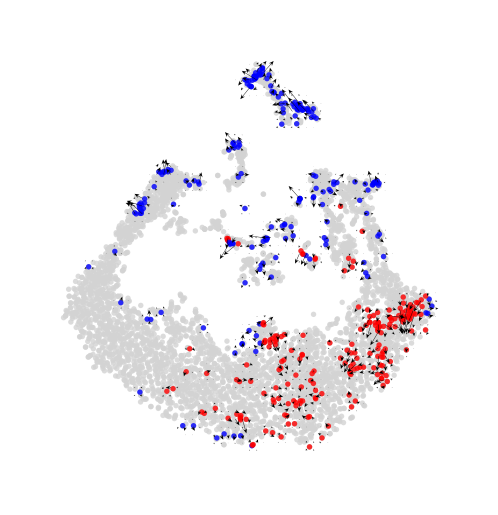

In [8]:
for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)

    adata = sc.read(config["path"]) 
    basis = config["basis"]
    clusters = config["cluster"]
    cluster_colors = config["cluster_colors"]
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    non_empty_indices = adata.uns['non_empty_indices']
    upper_n = upper[non_empty_indices]

    dis = np.subtract(upper_n,best)
    high_indices = np.argpartition(dis, -200)[-200:]
    low_indices = np.argpartition(dis, 200)[:200]
    adata.obs['highlight'] = 'Other'
    subset_barcodes = adata.obs.index[non_empty_indices]

    high_barcodes = subset_barcodes[high_indices]
    low_barcodes = subset_barcodes[low_indices]
    adata.obs.loc[high_barcodes, 'highlight'] = 'Target Cells'
    adata.obs.loc[low_barcodes, 'highlight'] = 'Low Cells'
    adata_plot = bestVelocityEmbedded(adata, basis=basis, clusters=clusters, cluster_colors=cluster_colors)

    # Plotting
    cm = 1 / 2.54 
    figsize=(3 * cm, 2.4 * cm)
    fig, ax = plt.subplots(dpi=450, figsize=figsize)
    ax.set(xticks=[], yticks=[])
    pl = scvelo.pl.velocity_embedding_grid(adata_plot, 
                                    basis=basis, 
                                    color='highlight', 
                                    groups=['Low Cells', 'Target Cells'], 
                                    palette={'Target Cells': 'red', 'Other': 'lightgrey', 'Low Cells': 'blue'},
                                    show=False, size=3,rasterized=True, figsize=figsize,alpha=0.8,
                                    ax=ax, frameon=False, xlabel='', ylabel='', title ='',
                                    arrow_color='black', edgecolors=None,
                                    linewidth=.25, arrow_size=2, arrow_length=1, )
    ax.set_aspect('equal')
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    pl.set_rasterized(True)
    plt.savefig(f"/mnt/volume/Johanna_Velotest/results/bounds/{name}_highlighted_cells_200.pdf", transparent=True, dpi=450)
    plt.show()

### Plot the distances as overview

Pancreas_dynamical


Pancreas_stochastic
Dentate_gyrus
Gastrulation_erythroid
Bone_marrow
PBMC
Covid
Retinal_development
Human_HSC
RPE_1
Hindbrain_mouse
Oligodendrocyte_mouse
Bone_marrow_mouse
Cerebral_cortex_human
Hematopoiesis_mouse
Spermatogenisis
Old_brain
Prefrontal_cortex
Intestinal_organoids
Zebra_NMP


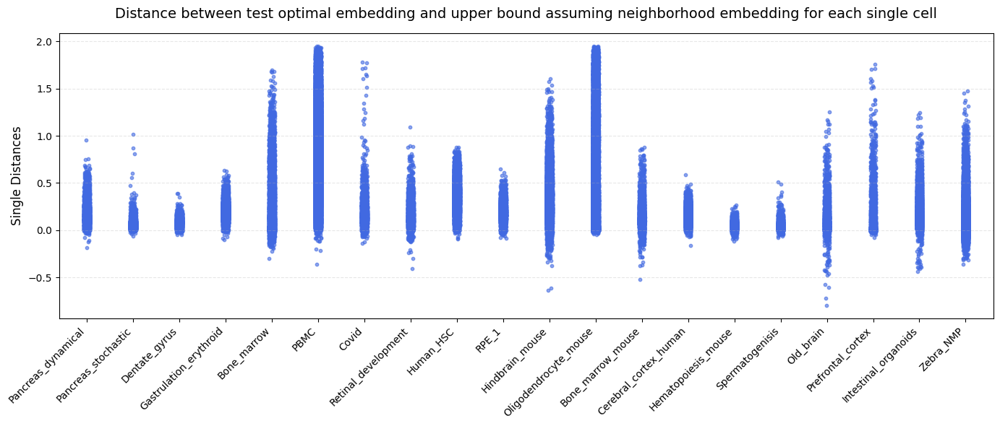

In [11]:
plotset = {}

for name, path in datasets.items():
    print(name)
    # Calculte PCA and original values
    with open(path, "r") as f:
        config = yaml.safe_load(f)

    # Extrakt infomation anndata object
    adata = sc.read(config["path"]) 
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    non_empty_indices = adata.uns['non_empty_indices']
    upper_n = upper[non_empty_indices]

    # Prepare response
    distances = np.subtract(upper_n, best)
    plotset[name] = distances

fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

for i, name in enumerate(plotset):
    x_base = i
    y_values = plotset[name]
    x_jittered = add_jitter(x_base, y_values)
    ax.scatter(x_jittered, y_values, s=10, alpha=0.6, label=name, color="royalblue")

ax.set_xticks(range(len(plotset)))
ax.set_xticklabels(plotset, rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(plotset) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Single Distances", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding for each single cell", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

### Plot cell that have a distance below 0 

Dropping all the genes which are not velocity genes. 1027 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:24<00:00, 153.41it/s]


Exclusion radius in rad: 0.17453292519943295


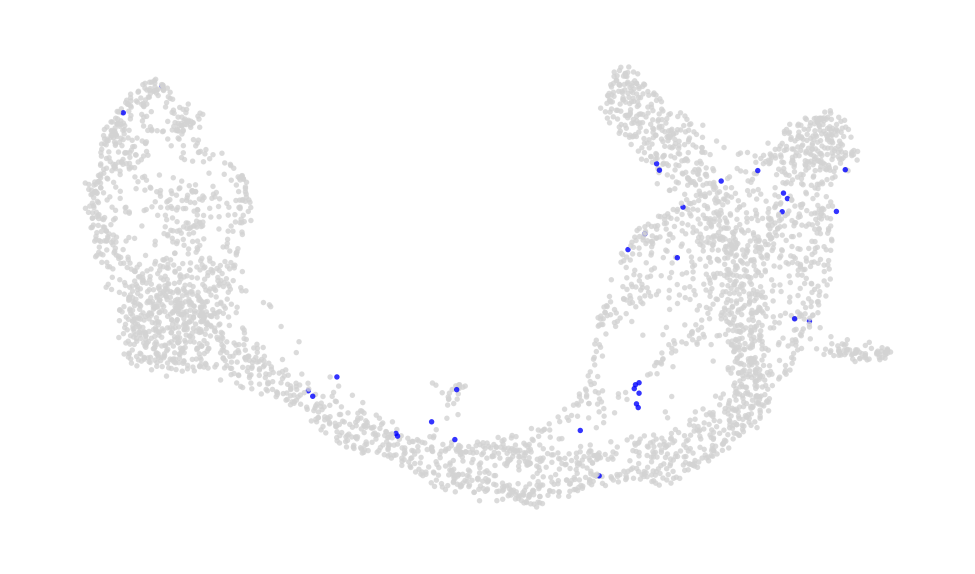

Dropping all the genes which are not velocity genes. 1038 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:24<00:00, 148.81it/s]


Exclusion radius in rad: 0.17453292519943295


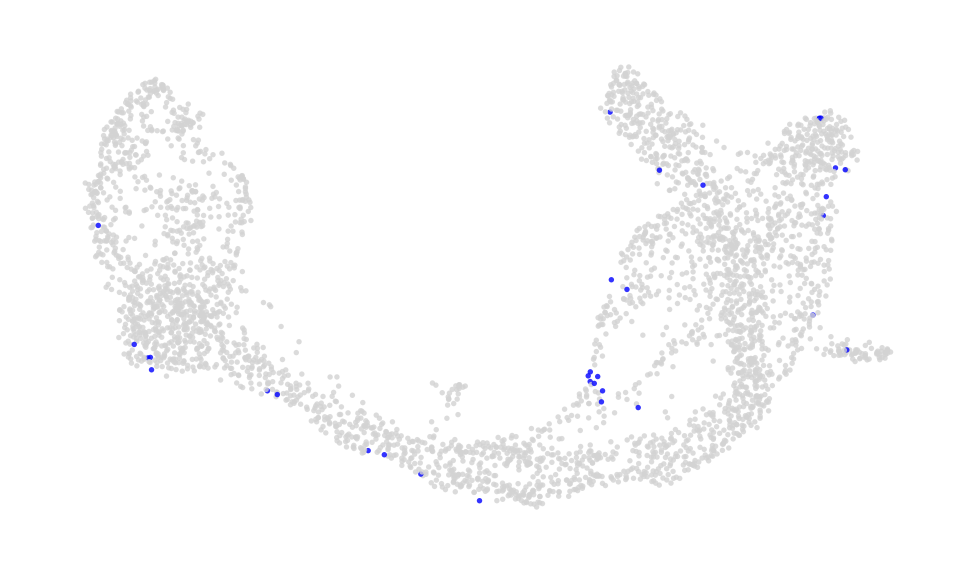

Dropping all the genes which are not velocity genes. 557 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2930/2930 [00:19<00:00, 146.94it/s]


Exclusion radius in rad: 0.17453292519943295


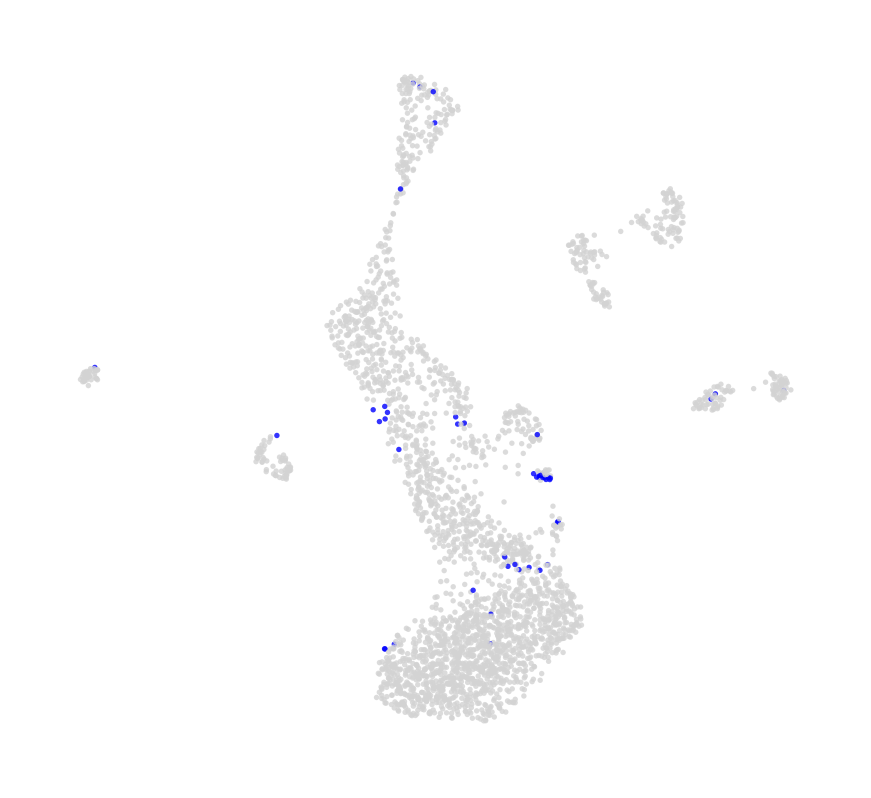

Dropping all the genes which are not velocity genes. 488 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 9815/9815 [01:04<00:00, 151.77it/s]


Exclusion radius in rad: 0.17453292519943295


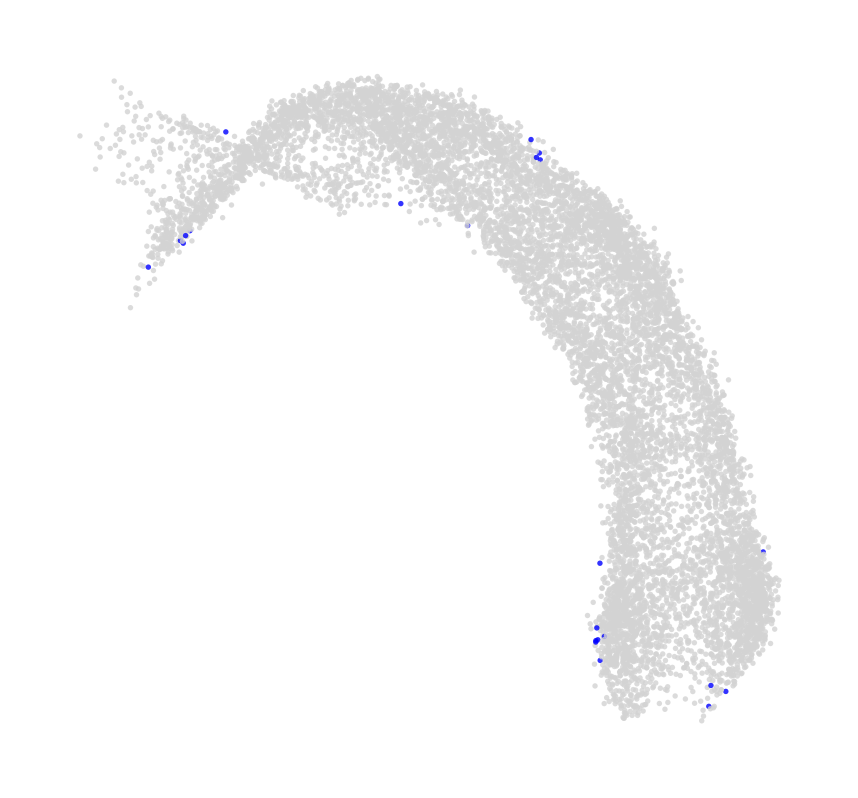

Dropping all the genes which are not velocity genes. 451 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 5780/5780 [00:36<00:00, 156.97it/s]


Exclusion radius in rad: 0.17453292519943295


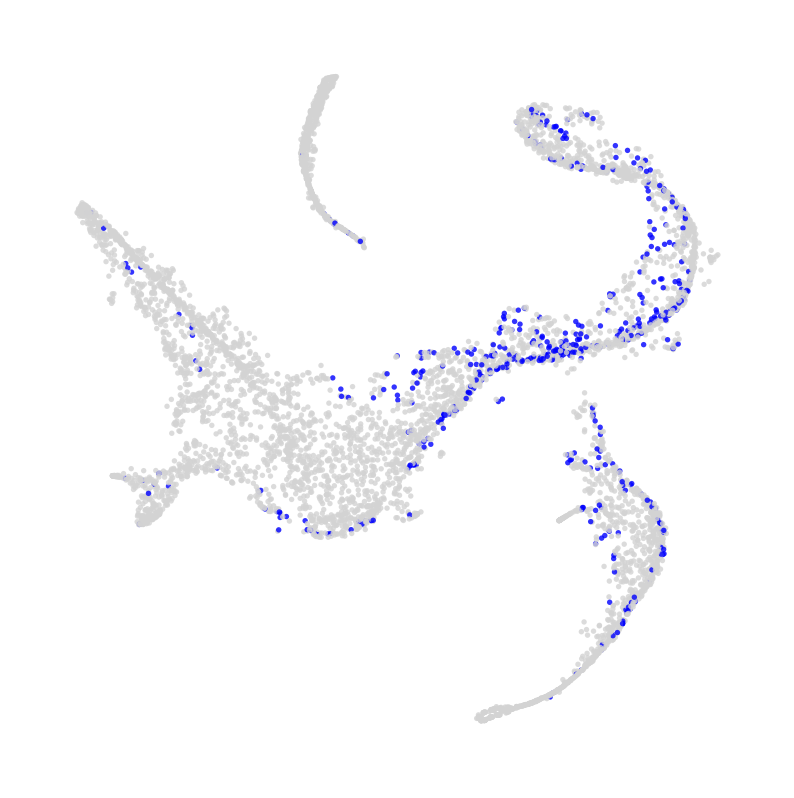

Dropping all the genes which are not velocity genes. 12 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 65877/65877 [13:21<00:00, 82.21it/s] 


Exclusion radius in rad: 0.17453292519943295


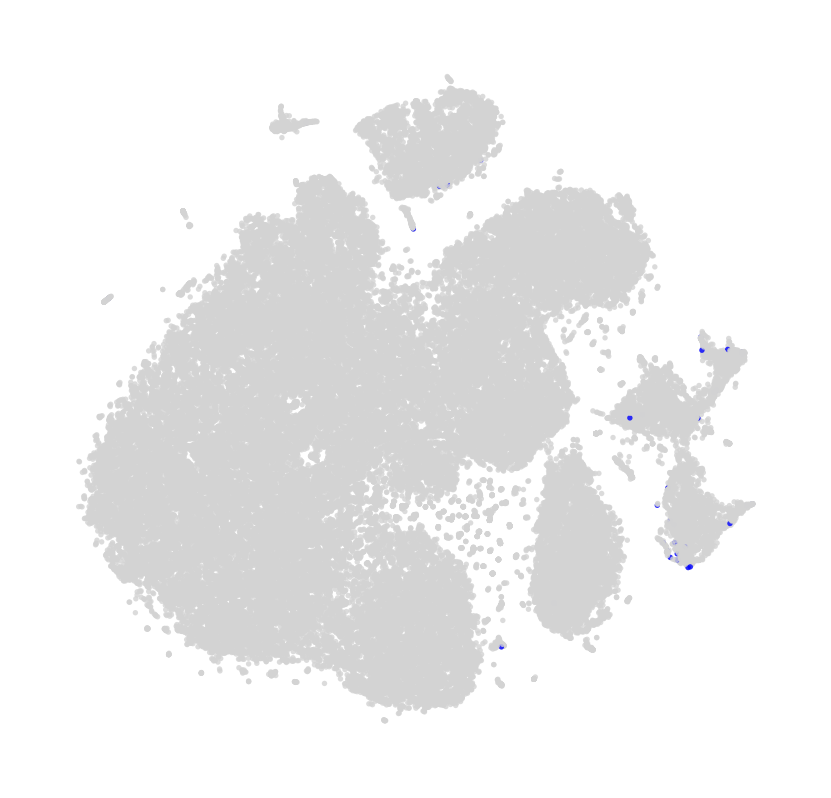

Dropping all the genes which are not velocity genes. 126 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3076/3076 [00:19<00:00, 157.13it/s]


Exclusion radius in rad: 0.17453292519943295


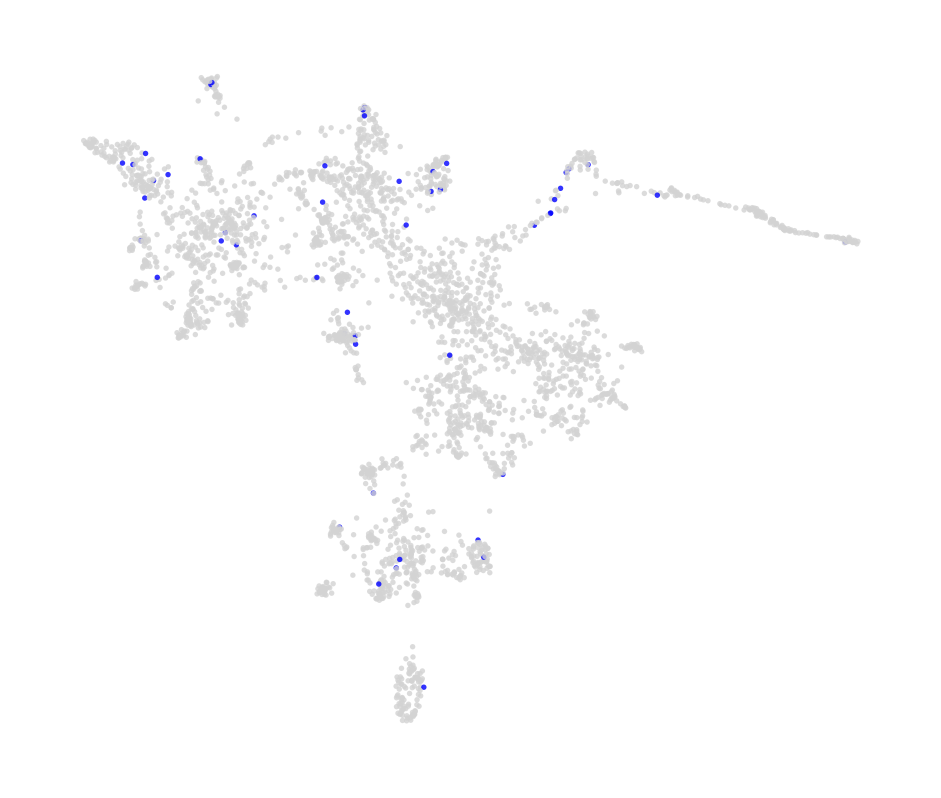

Dropping all the genes which are not velocity genes. 677 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2726/2726 [00:18<00:00, 150.61it/s]


Exclusion radius in rad: 0.17453292519943295


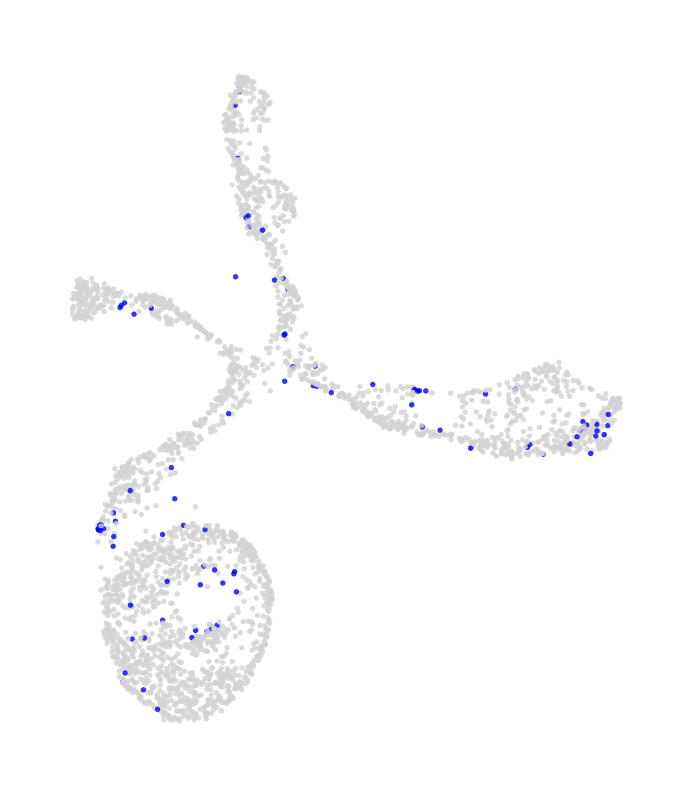

Dropping all the genes which are not velocity genes. 328 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 11605/11605 [01:16<00:00, 151.90it/s]


Exclusion radius in rad: 0.17453292519943295


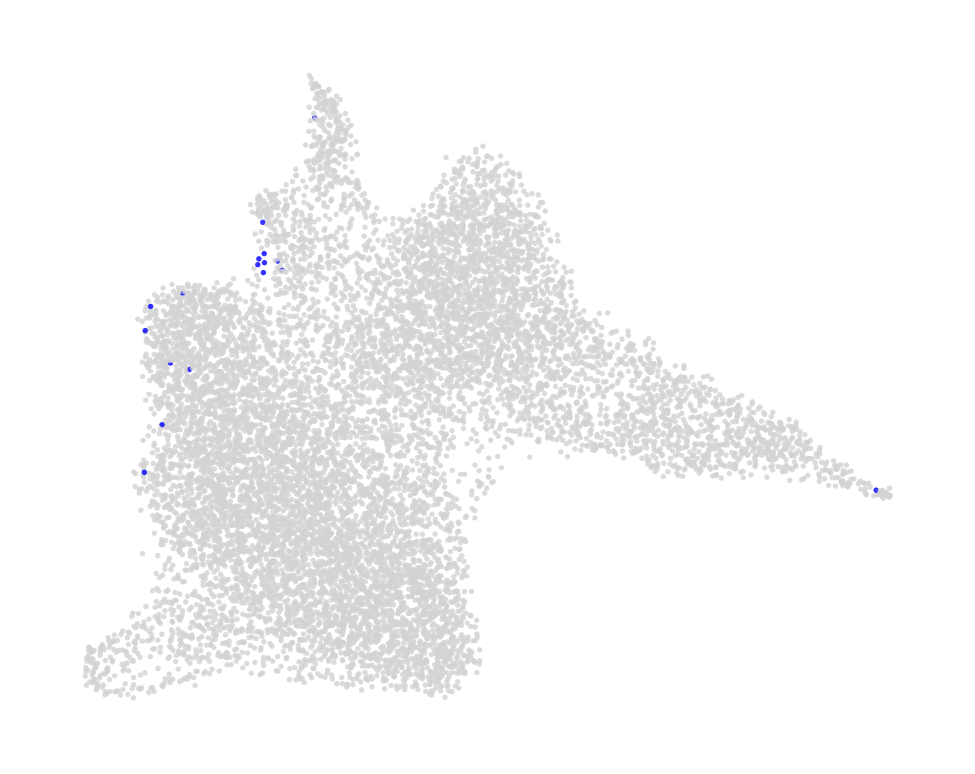

Dropping all the genes which are not velocity genes. 387 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 5422/5422 [00:34<00:00, 157.93it/s]


Exclusion radius in rad: 0.17453292519943295


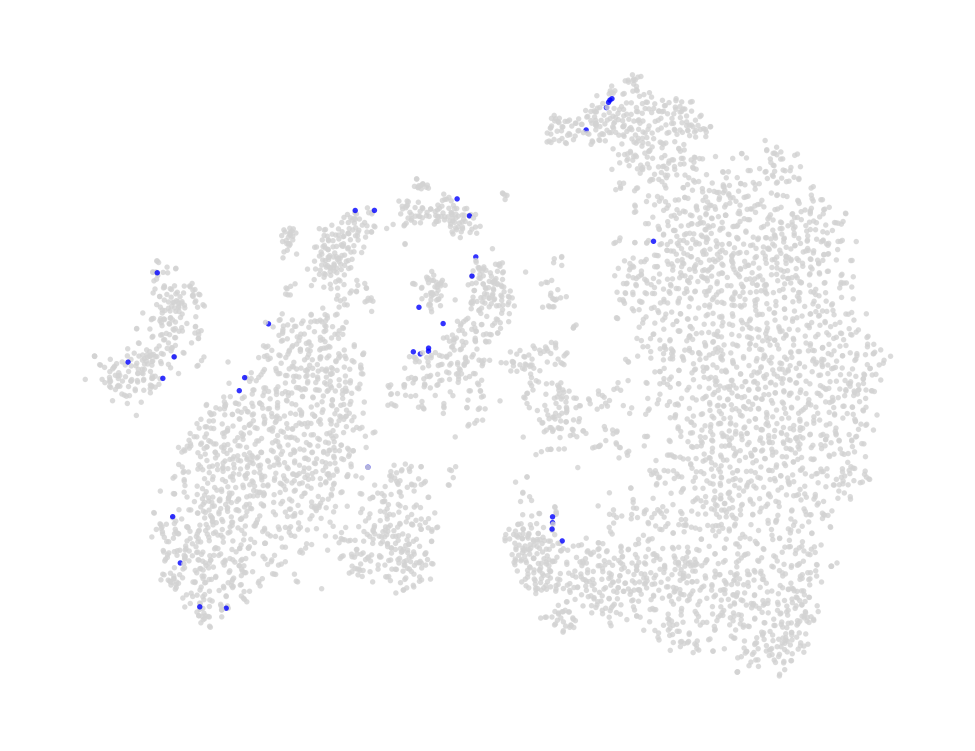

Dropping all the genes which are not velocity genes. 288 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 13501/13501 [01:30<00:00, 148.60it/s]


Exclusion radius in rad: 0.17453292519943295


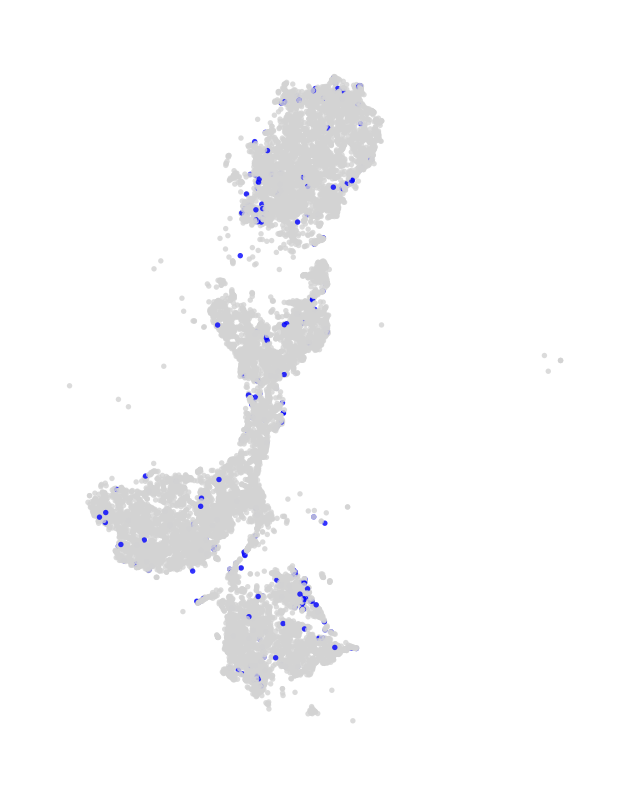

Dropping all the genes which are not velocity genes. 384 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 36146/36146 [05:31<00:00, 109.05it/s]


Exclusion radius in rad: 0.17453292519943295


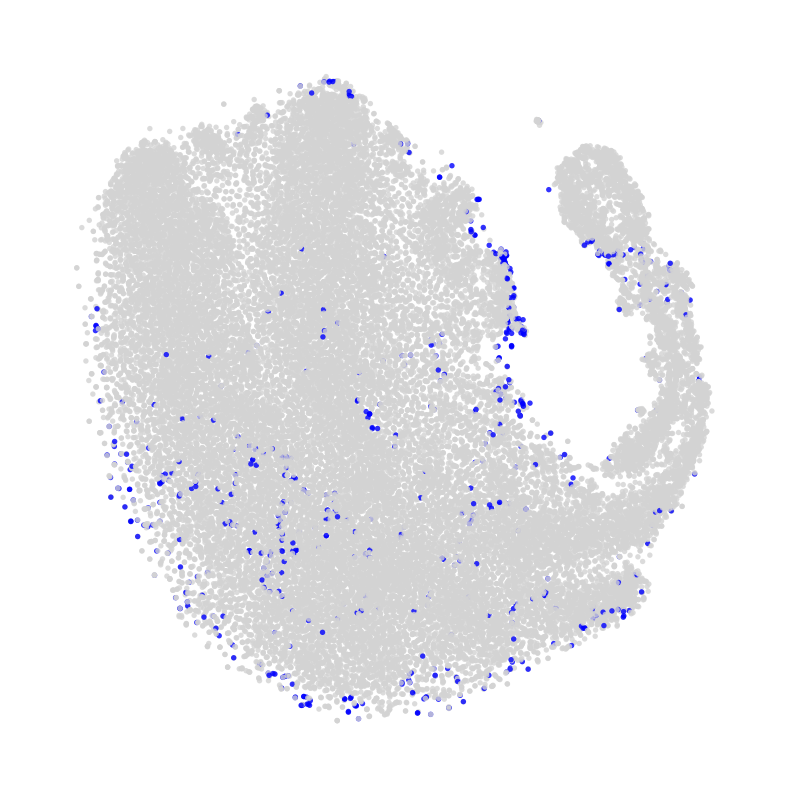

Dropping all the genes which are not velocity genes. 592 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2600/2600 [00:17<00:00, 149.87it/s]


Exclusion radius in rad: 0.17453292519943295


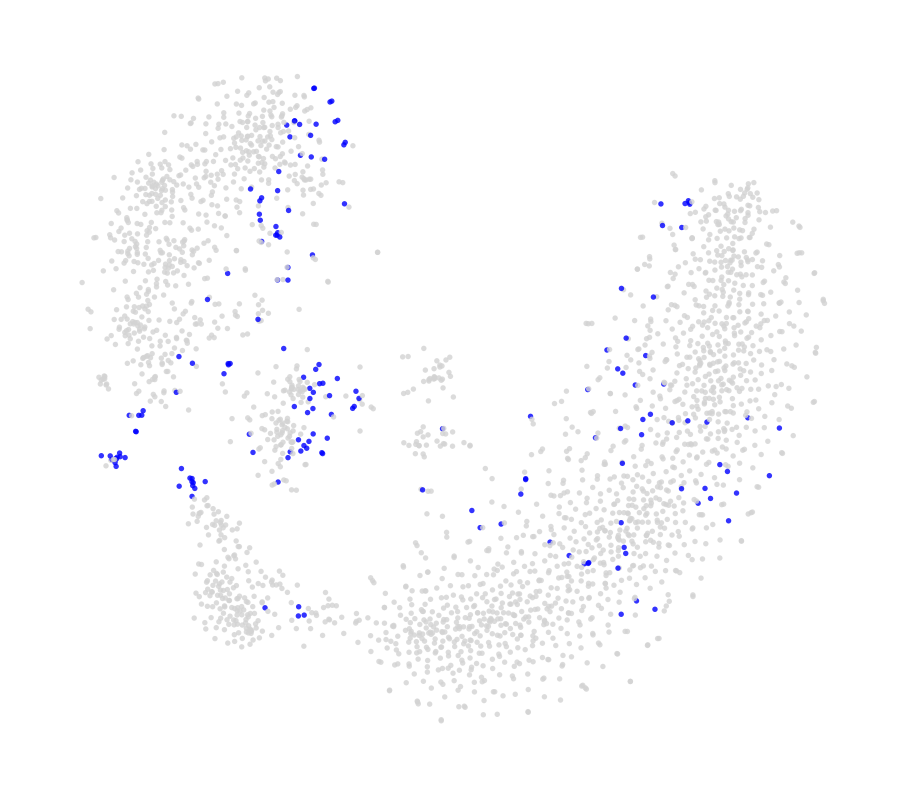

Dropping all the genes which are not velocity genes. 351 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 4693/4693 [00:29<00:00, 158.51it/s]


Exclusion radius in rad: 0.17453292519943295


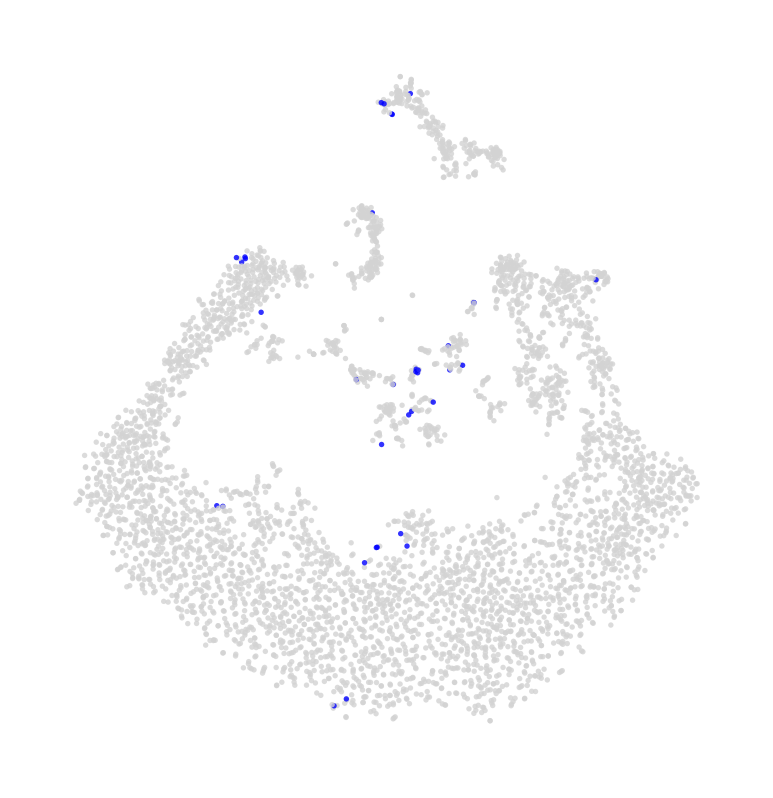

Dropping all the genes which are not velocity genes. 1218 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1772/1772 [00:12<00:00, 143.85it/s]


Exclusion radius in rad: 0.17453292519943295


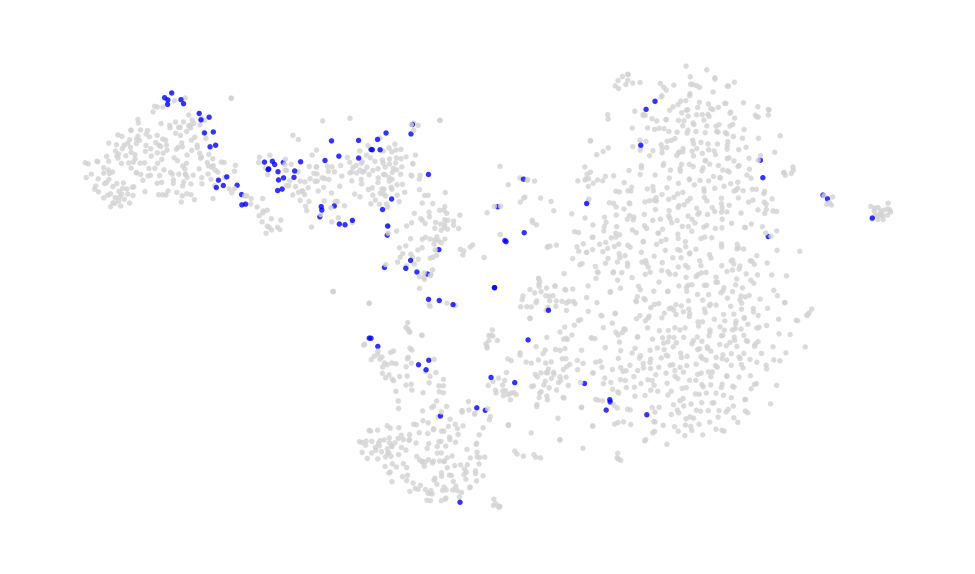

Dropping all the genes which are not velocity genes. 299 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1829/1829 [00:12<00:00, 142.30it/s]


Exclusion radius in rad: 0.17453292519943295


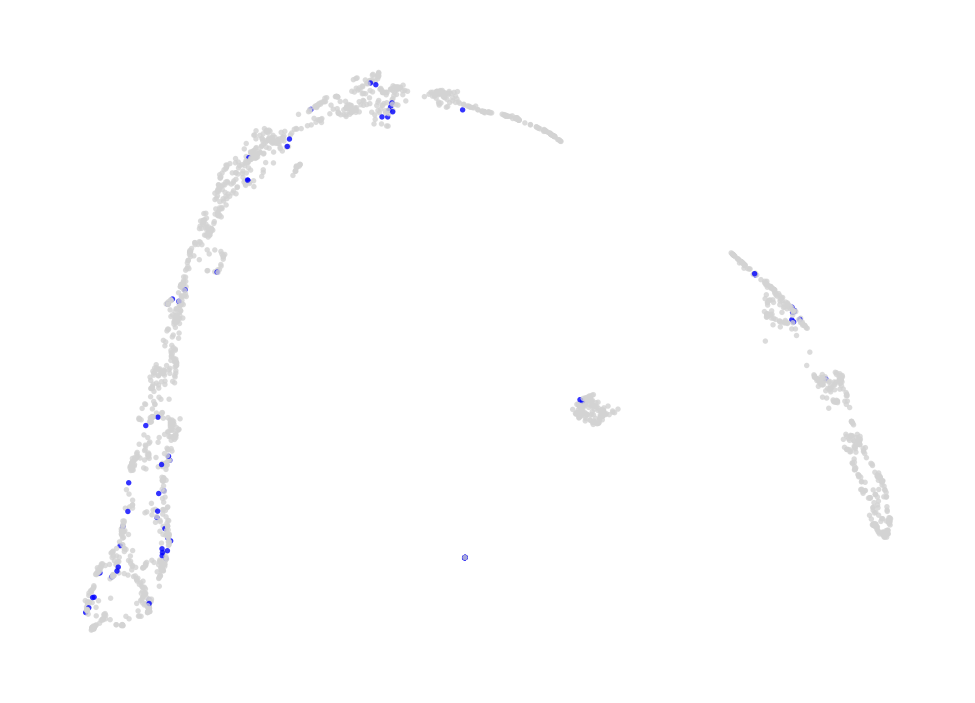

Dropping all the genes which are not velocity genes. 1302 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1823/1823 [00:12<00:00, 143.05it/s]


Exclusion radius in rad: 0.17453292519943295


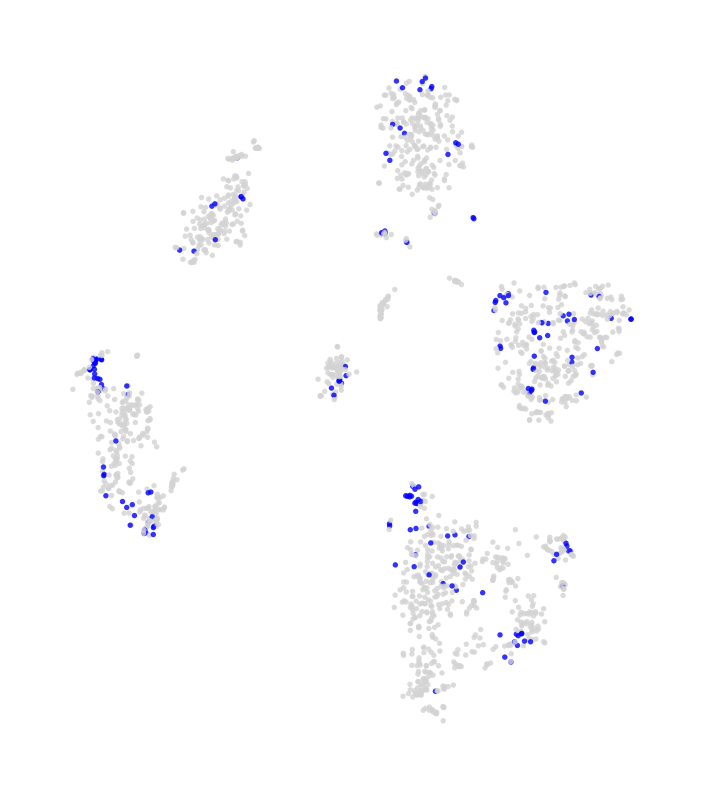

Dropping all the genes which are not velocity genes. 1232 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1267/1267 [00:09<00:00, 135.19it/s]


Exclusion radius in rad: 0.17453292519943295


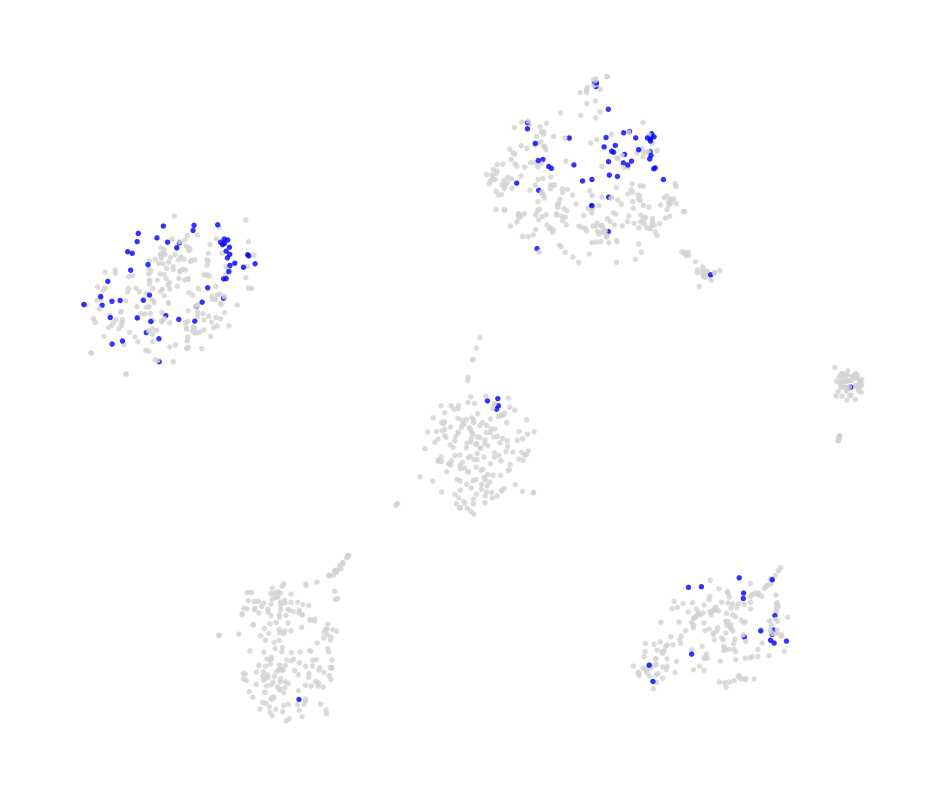

Dropping all the genes which are not velocity genes. 156 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3831/3831 [00:25<00:00, 151.84it/s]


Exclusion radius in rad: 0.17453292519943295


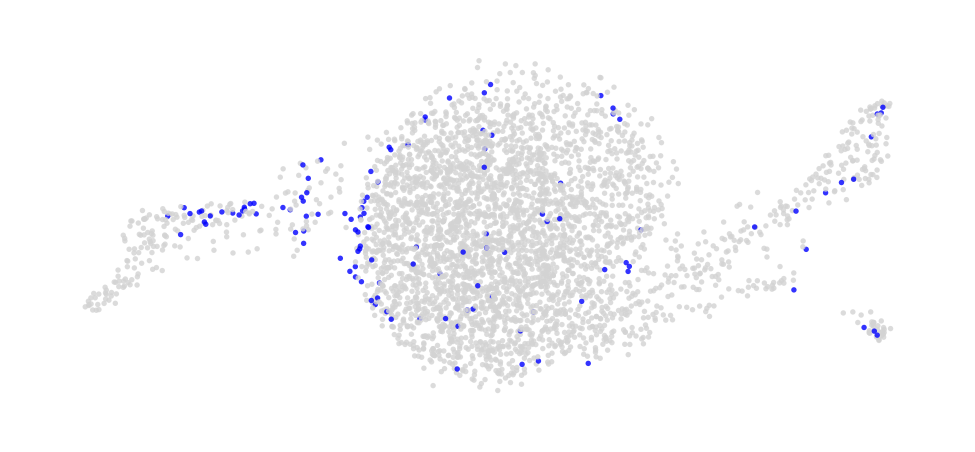

Dropping all the genes which are not velocity genes. 897 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 16035/16035 [02:01<00:00, 131.61it/s]


Exclusion radius in rad: 0.17453292519943295


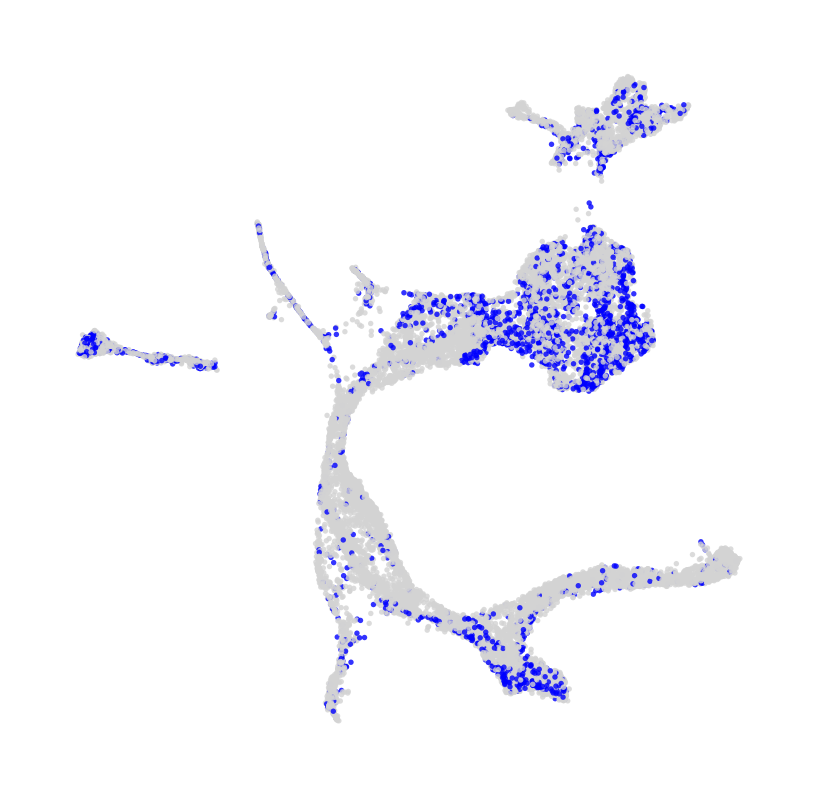

In [12]:
for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)

    adata = sc.read(config["path"]) 
    basis = config["basis"]
    clusters = config["cluster"]
    cluster_colors = config["cluster_colors"]
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    non_empty_indices = adata.uns['non_empty_indices']
    upper_n = upper[non_empty_indices]

    dis = np.subtract(upper_n,best)
    below_zero_indices = np.where(dis < 0)[0]
    if len(below_zero_indices) == 0:
        print(f"Skipping {name}: 0 cells found below zero.")
        continue
    adata.obs['highlight'] = 'Other'
    subset_barcodes = adata.obs.index[non_empty_indices]

    below_zero_barcodes = subset_barcodes[below_zero_indices]
    adata.obs.loc[below_zero_barcodes, 'highlight'] = 'Target Cells'
    adata_plot = bestVelocityEmbedded(adata, basis=basis, clusters=clusters, cluster_colors=cluster_colors)

    # Plotting
    cm = 1 / 2.54 
    figsize=(5 * cm, 4 * cm)
    fig, ax = plt.subplots(dpi=450, figsize=figsize)
    ax.set(xticks=[], yticks=[])
    pl = scvelo.pl.scatter(adata_plot, 
                                    basis=basis, 
                                    color='highlight', 
                                    palette={'Target Cells': 'blue', 'Other': 'lightgrey'},
                                    show=False, size=3,rasterized=True, figsize=figsize,alpha=0.8,
                                    ax=ax, frameon=False, xlabel='', ylabel='', title ='', legend_loc='none')
    ax.set_aspect('equal')
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    pl.set_rasterized(True)
    plt.savefig(f"/mnt/volume/Johanna_Velotest/results/bounds/{name}_highlighted_below_0.pdf", transparent=True, dpi=450)
    plt.show()

### Figure out how to find boarder cells of a plot 

Dropping all the genes which are not velocity genes. 1027 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:23<00:00, 159.10it/s]


Exclusion radius in rad: 0.17453292519943295
inner      3174
edge        472
Unknown      50
Name: count, dtype: int64


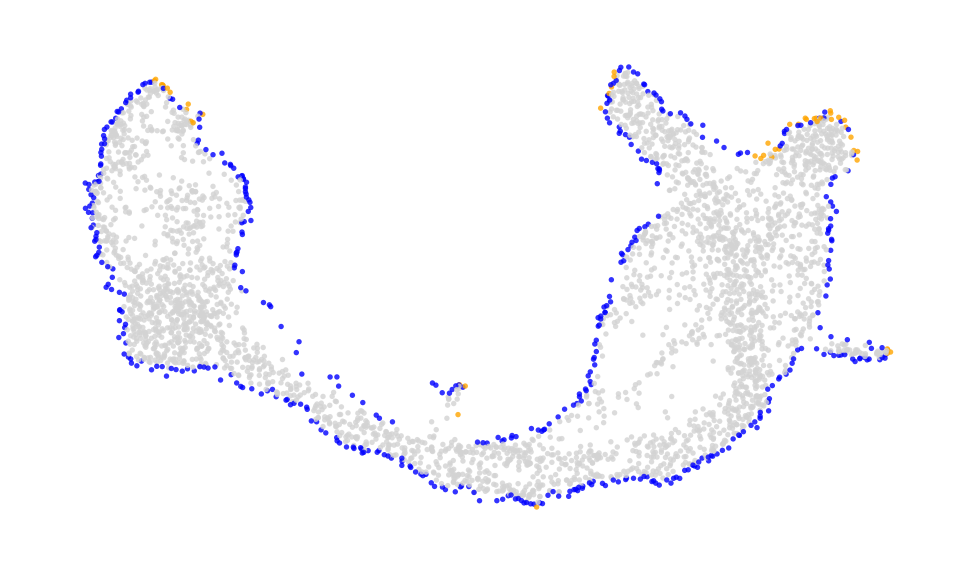

Dropping all the genes which are not velocity genes. 1038 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3696/3696 [00:23<00:00, 157.63it/s]


Exclusion radius in rad: 0.17453292519943295
inner      3178
edge        498
Unknown      20
Name: count, dtype: int64


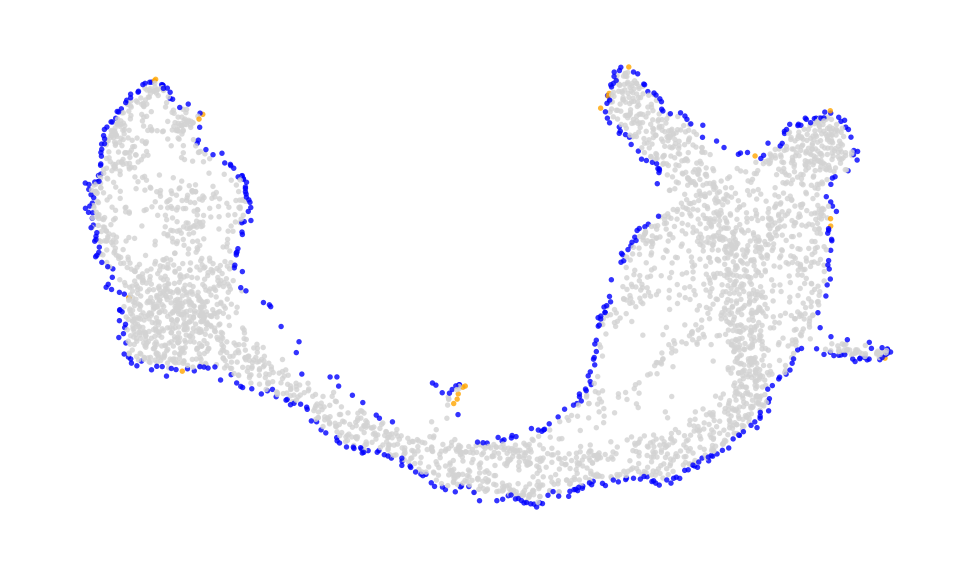

Dropping all the genes which are not velocity genes. 557 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2930/2930 [00:19<00:00, 152.65it/s]


Exclusion radius in rad: 0.17453292519943295
inner      2466
edge        432
Unknown      32
Name: count, dtype: int64


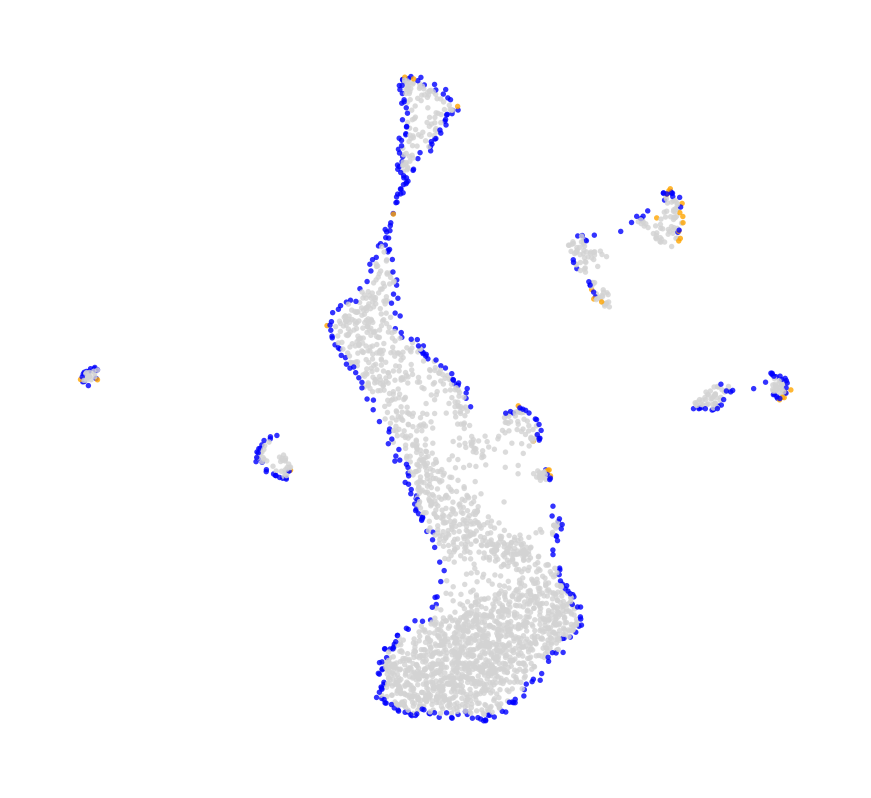

Dropping all the genes which are not velocity genes. 488 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 9815/9815 [01:03<00:00, 155.67it/s]


Exclusion radius in rad: 0.17453292519943295
inner      9312
edge        438
Unknown      65
Name: count, dtype: int64


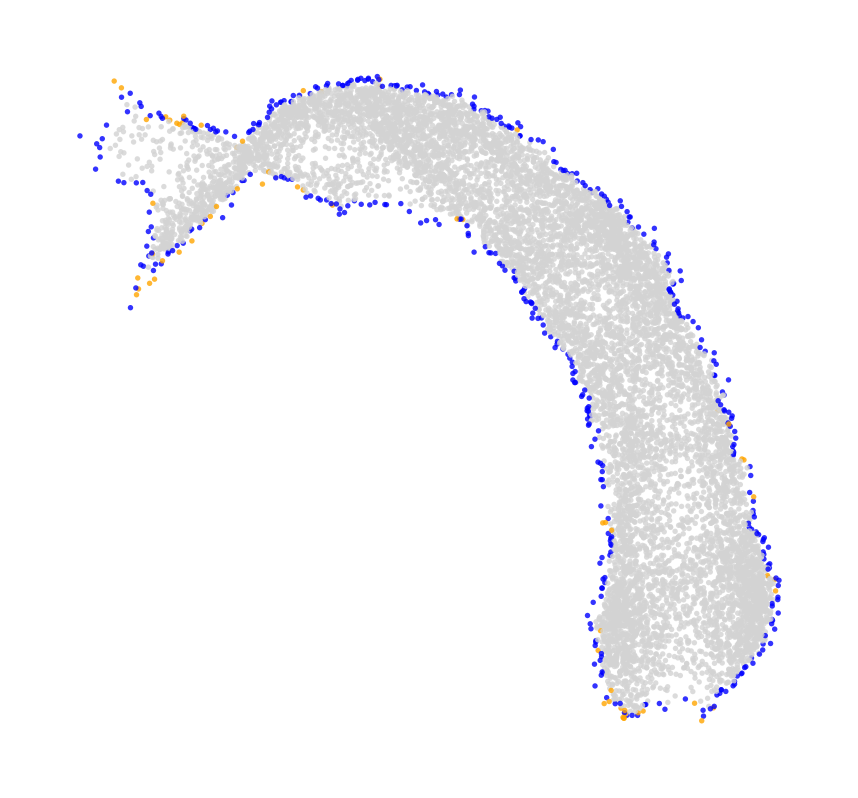

Dropping all the genes which are not velocity genes. 451 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 5780/5780 [00:36<00:00, 157.89it/s]


Exclusion radius in rad: 0.17453292519943295
inner      4251
edge       1281
Unknown     248
Name: count, dtype: int64


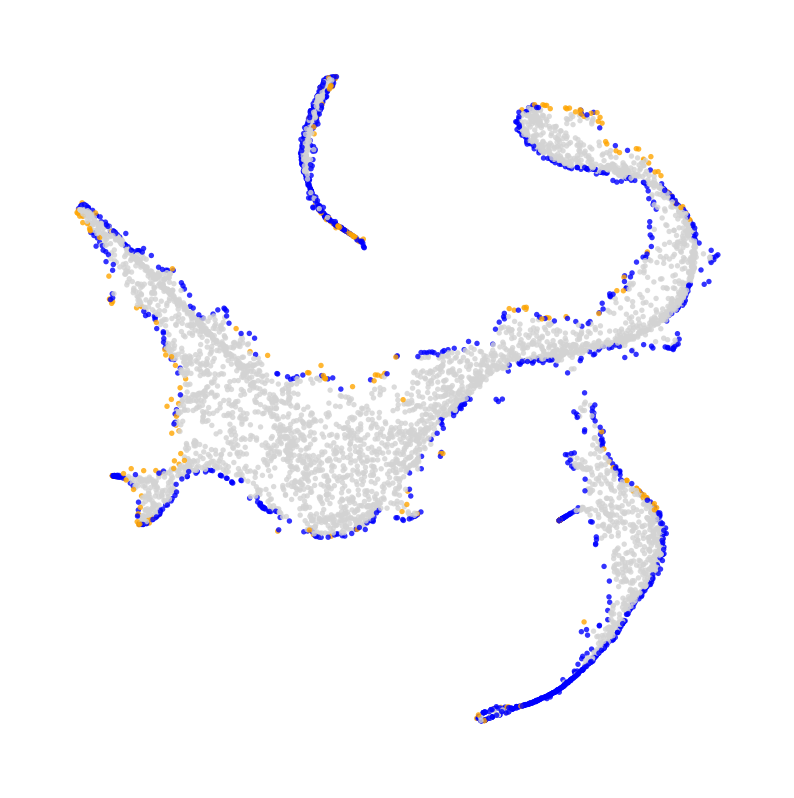

Dropping all the genes which are not velocity genes. 12 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 65877/65877 [12:49<00:00, 85.66it/s] 


Exclusion radius in rad: 0.17453292519943295
inner      63492
edge        1691
Unknown      694
Name: count, dtype: int64


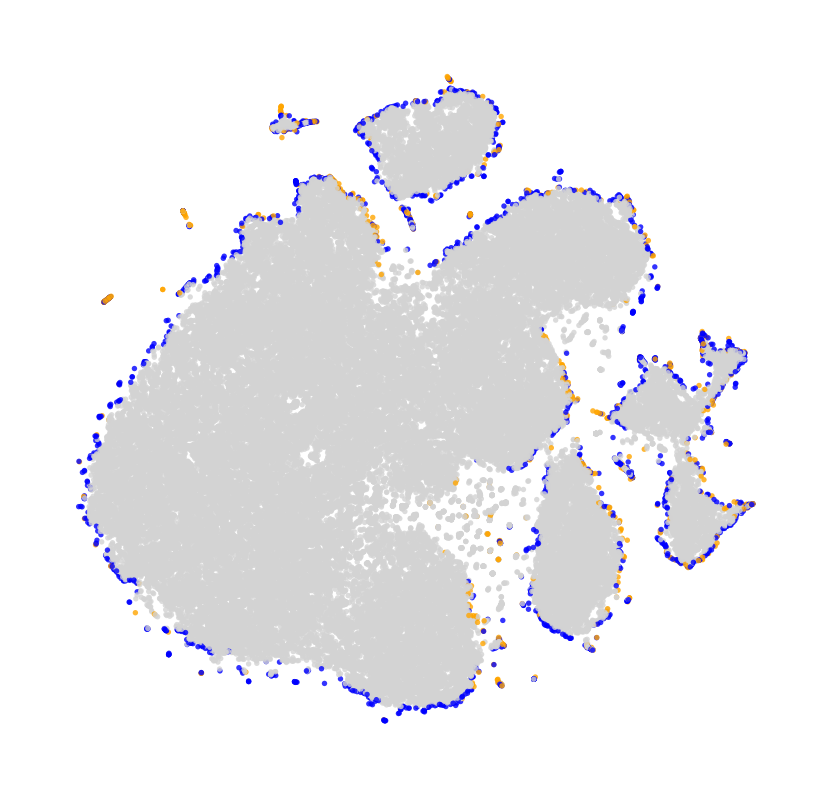

Dropping all the genes which are not velocity genes. 126 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3076/3076 [00:19<00:00, 157.44it/s]


Exclusion radius in rad: 0.17453292519943295
inner      2511
edge        446
Unknown     119
Name: count, dtype: int64


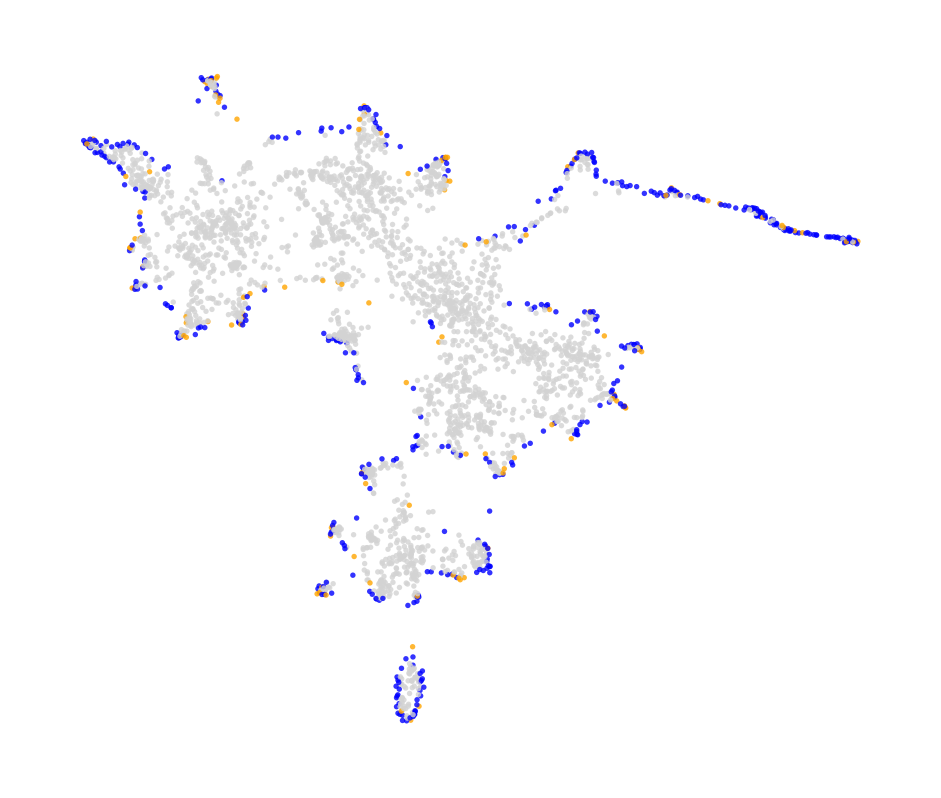

Dropping all the genes which are not velocity genes. 677 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2726/2726 [00:17<00:00, 153.47it/s]


Exclusion radius in rad: 0.17453292519943295
inner      2052
edge        618
Unknown      56
Name: count, dtype: int64


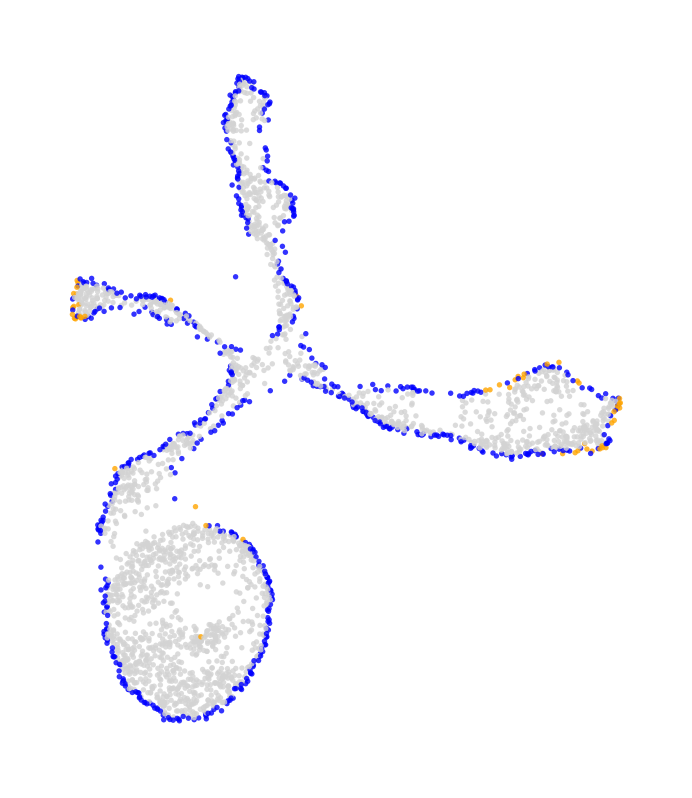

Dropping all the genes which are not velocity genes. 328 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 11605/11605 [01:16<00:00, 152.38it/s]


Exclusion radius in rad: 0.17453292519943295
inner      11123
edge         400
Unknown       82
Name: count, dtype: int64


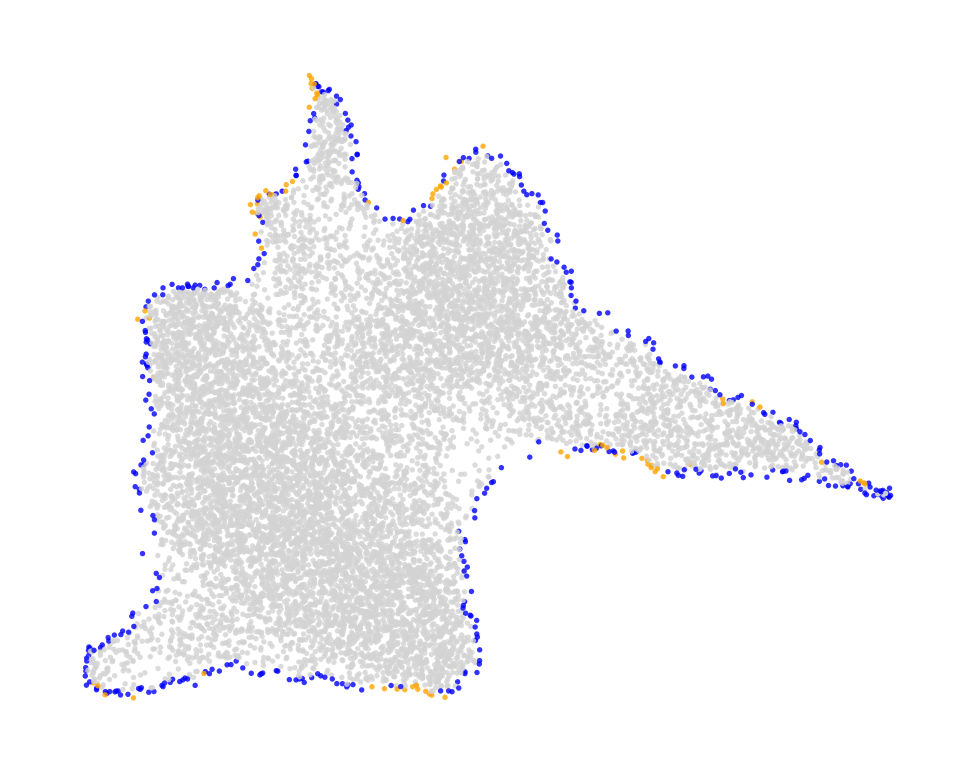

Dropping all the genes which are not velocity genes. 387 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 5422/5422 [00:34<00:00, 159.26it/s]


Exclusion radius in rad: 0.17453292519943295
inner      5040
edge        301
Unknown      81
Name: count, dtype: int64


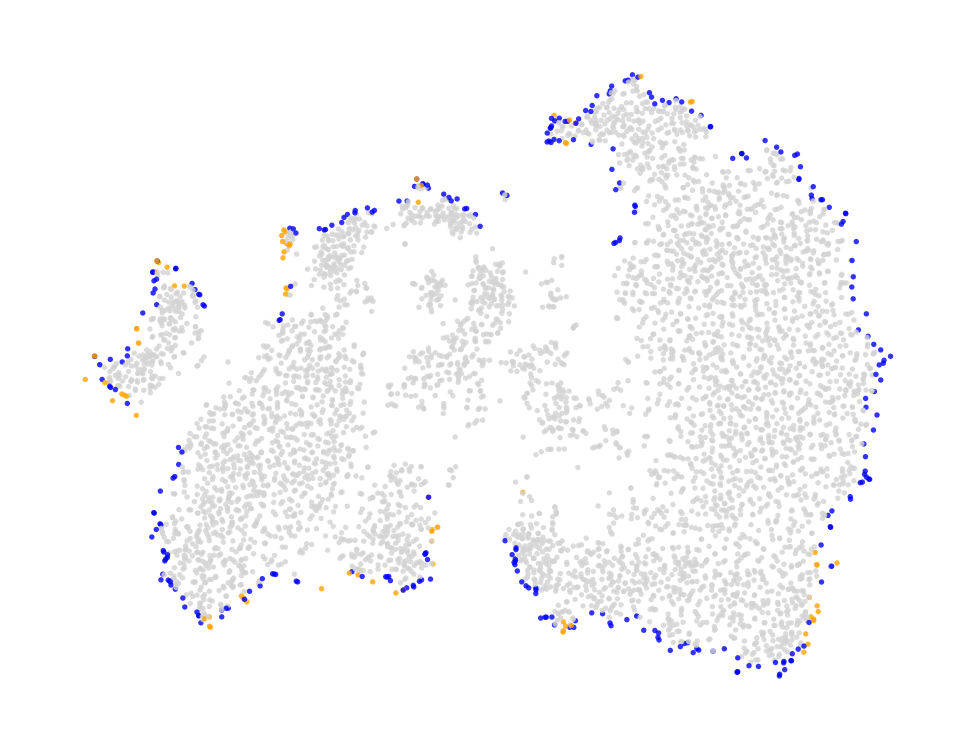

Dropping all the genes which are not velocity genes. 288 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 13501/13501 [01:33<00:00, 143.94it/s]


Exclusion radius in rad: 0.17453292519943295
inner      12358
edge         909
Unknown      234
Name: count, dtype: int64


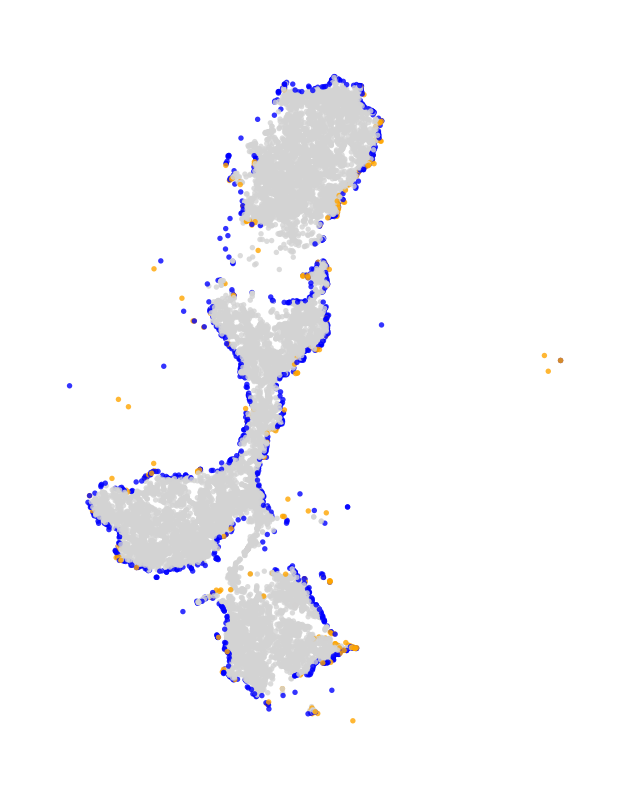

Dropping all the genes which are not velocity genes. 384 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 36146/36146 [05:22<00:00, 112.19it/s]


Exclusion radius in rad: 0.17453292519943295
inner      35239
edge         821
Unknown       86
Name: count, dtype: int64


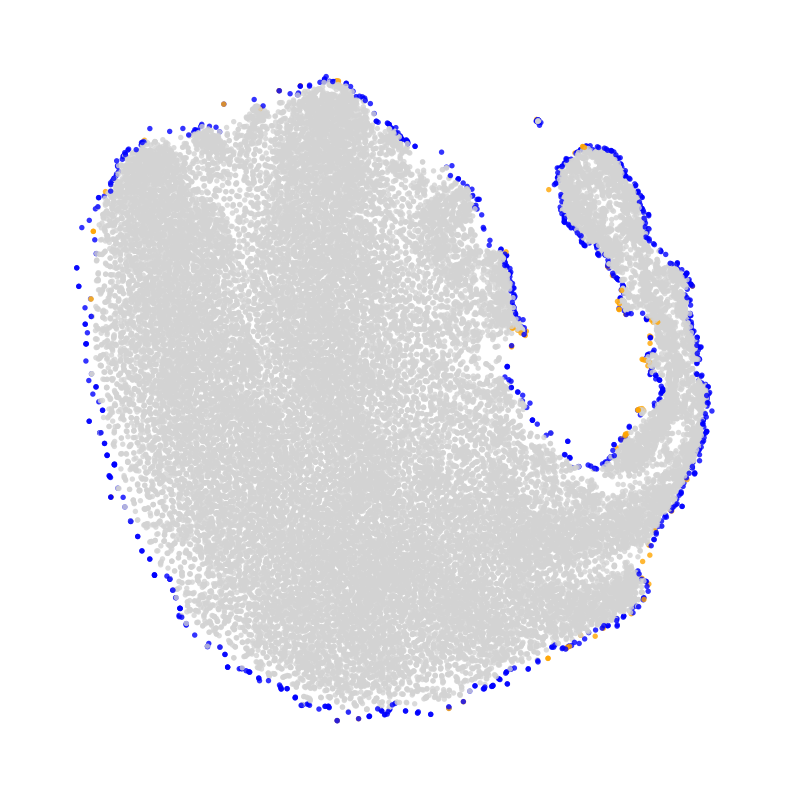

Dropping all the genes which are not velocity genes. 592 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 2600/2600 [00:16<00:00, 153.10it/s]


Exclusion radius in rad: 0.17453292519943295
inner      2378
edge        182
Unknown      40
Name: count, dtype: int64


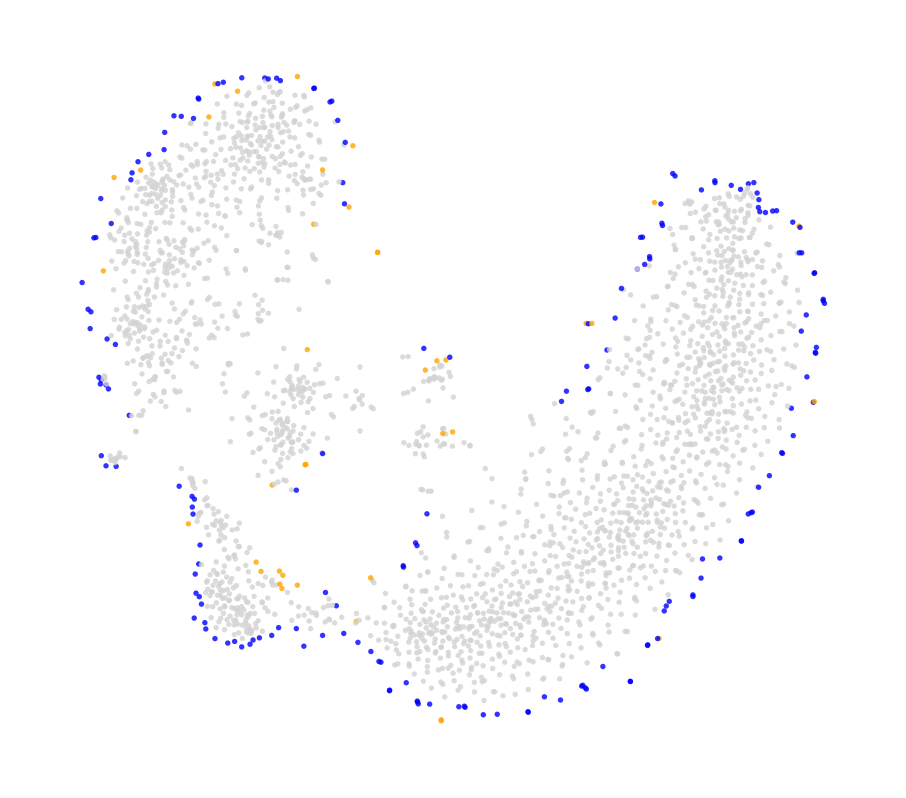

Dropping all the genes which are not velocity genes. 351 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 4693/4693 [00:31<00:00, 150.21it/s]


Exclusion radius in rad: 0.17453292519943295
inner      4160
edge        480
Unknown      53
Name: count, dtype: int64


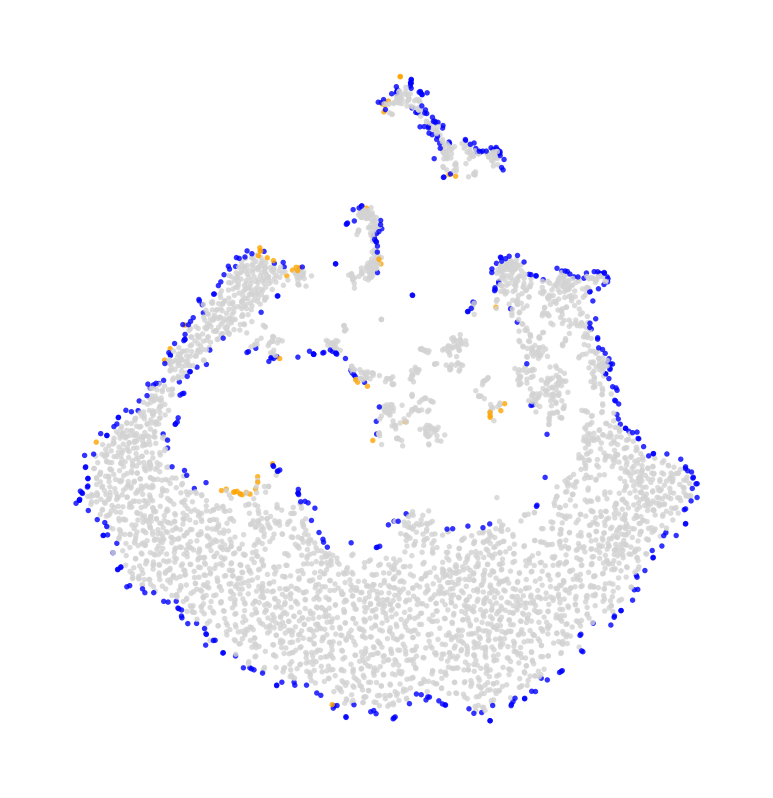

Dropping all the genes which are not velocity genes. 1218 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1772/1772 [00:12<00:00, 146.90it/s]


Exclusion radius in rad: 0.17453292519943295
inner      1565
edge        187
Unknown      20
Name: count, dtype: int64


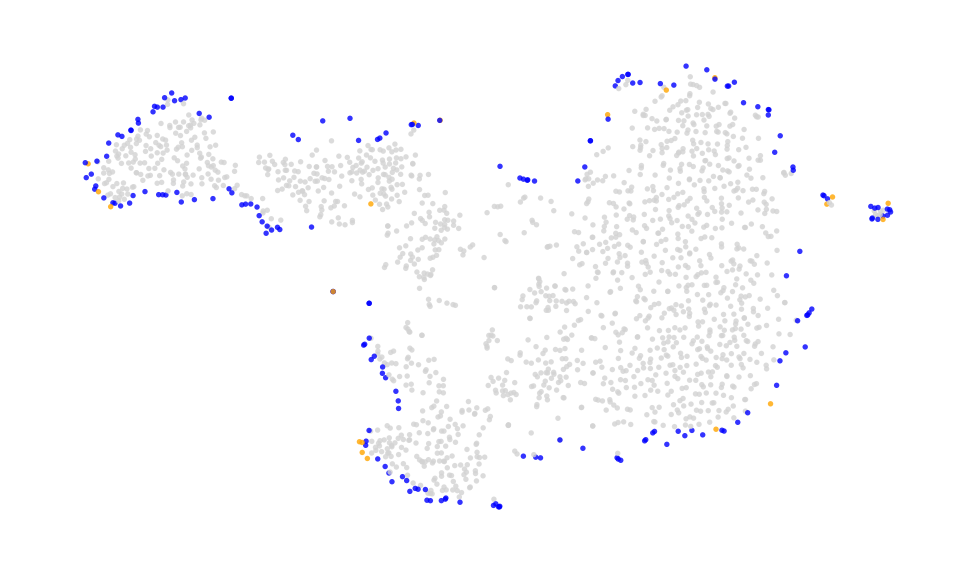

Dropping all the genes which are not velocity genes. 299 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1829/1829 [00:12<00:00, 141.80it/s]


Exclusion radius in rad: 0.17453292519943295
inner      951
edge       816
Unknown     62
Name: count, dtype: int64


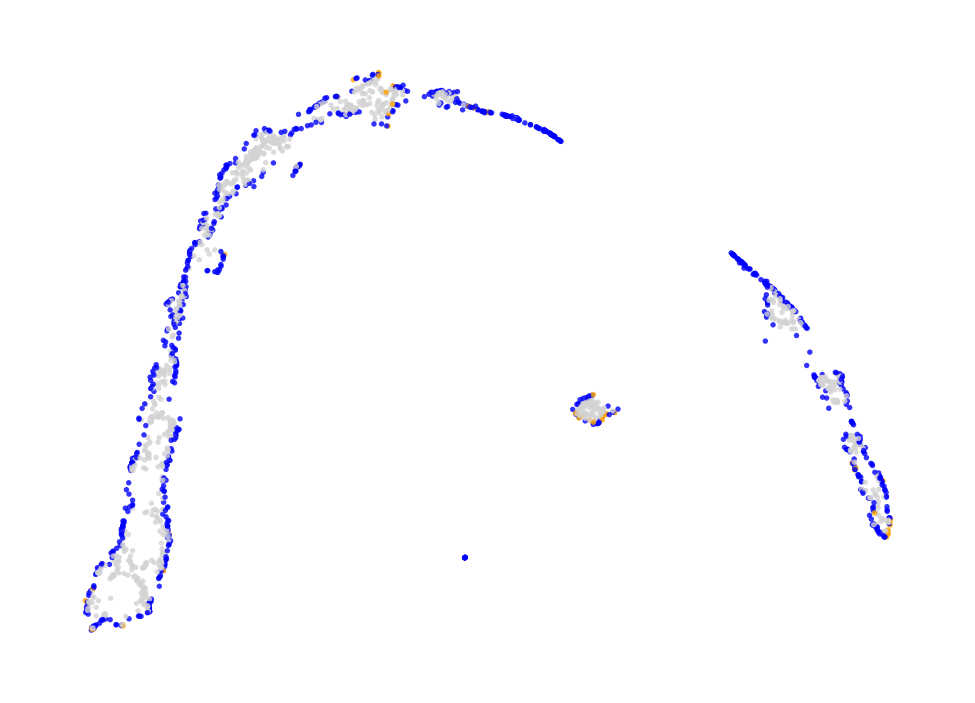

Dropping all the genes which are not velocity genes. 1302 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1823/1823 [00:12<00:00, 144.04it/s]


Exclusion radius in rad: 0.17453292519943295
inner      1423
edge        314
Unknown      86
Name: count, dtype: int64


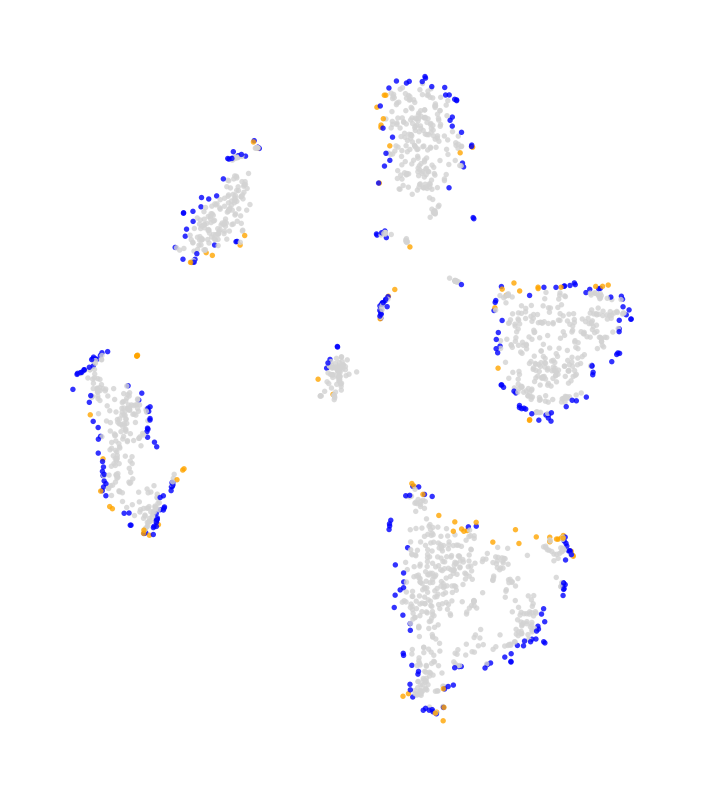

Dropping all the genes which are not velocity genes. 1232 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 1267/1267 [00:09<00:00, 136.95it/s]


Exclusion radius in rad: 0.17453292519943295
inner      925
edge       263
Unknown     79
Name: count, dtype: int64


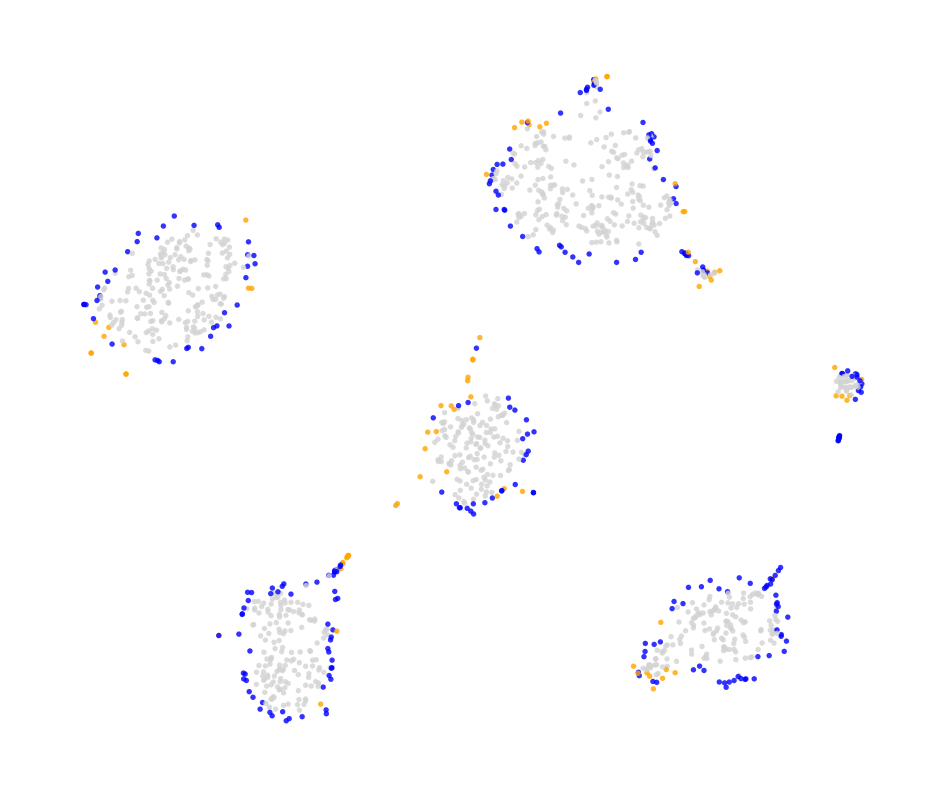

Dropping all the genes which are not velocity genes. 156 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 3831/3831 [00:24<00:00, 156.93it/s]


Exclusion radius in rad: 0.17453292519943295
inner      3550
edge        232
Unknown      49
Name: count, dtype: int64


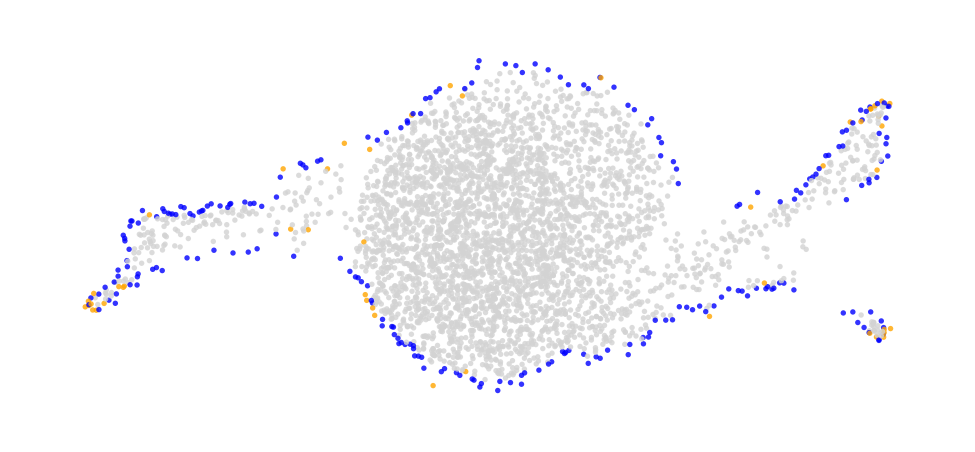

Dropping all the genes which are not velocity genes. 897 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 16035/16035 [01:58<00:00, 135.25it/s]


Exclusion radius in rad: 0.17453292519943295
inner      13760
edge        2011
Unknown      264
Name: count, dtype: int64


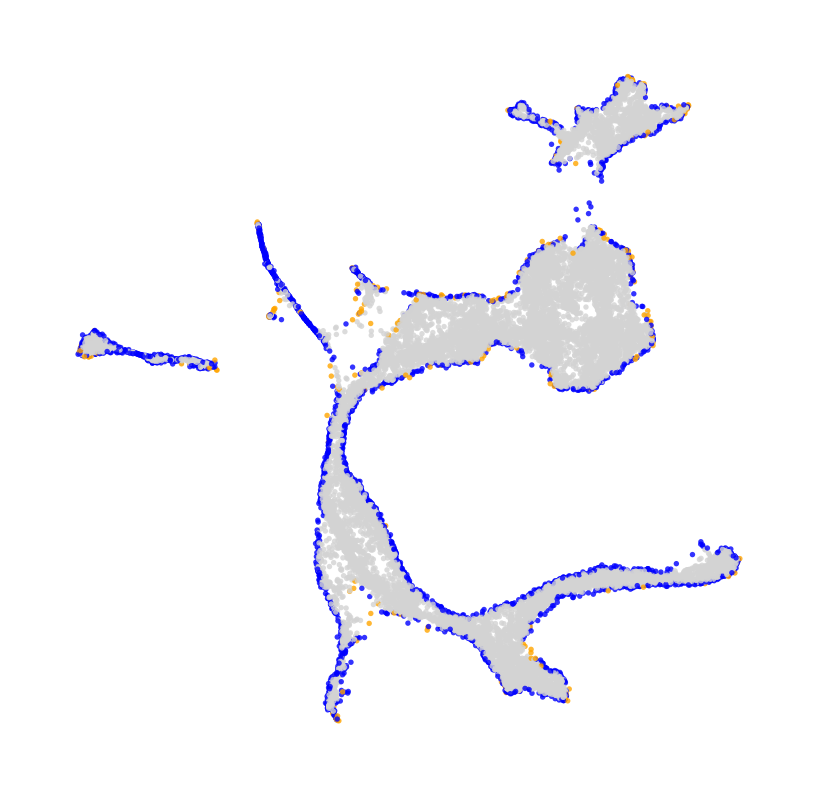

In [6]:
plotset = {}
for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)
    # Extract data and parameters from the config
    adata = sc.read(config["path"]) 
    basis = config["basis"]
    clusters = config["cluster"]
    cluster_colors = config["cluster_colors"]
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    non_empty_indices = adata.uns['non_empty_indices']
    upper_n = upper[non_empty_indices]

    # Rerun velotest to get the statistics for the current dataset
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, basis=basis, 
                                                                           number_neighbors_to_sample_from=200, 
                                                                           null_distribution="velocities-explicit", 
                                                                           cosine_empty_neighborhood=None, 
                                                                           correction="bonferroni", 
                                                                           restrict_to_velocity_genes=True, 
                                                                           exclusion_degree=10)
    statistics = debug_dict['statistics']
    for i, p_val in enumerate(uncorrected_p_values):
            if p_val == 2:
                statistics[i] = None
    non_empty_neighborhoods_indices = np.where(uncorrected_p_values != 2)[0]

    # Determine cell positions based on the gaps in the angular domain
    cell_position = []
    gap_threshold = math.radians(45)
    full_circle = 2 * np.pi
    for i in range(len(statistics)):
        if statistics[i] is not None:
            radiaans = statistics[i].get_domain()
            gaps = []
            for j in range(len(radiaans)-1):
                gap = (radiaans[j+1][0] - radiaans[j][1])
                gaps.append(gap)
            # Check last end to start
            wrap_gap = radiaans[0][0] + (full_circle - radiaans[-1][1])
            gaps.append(wrap_gap)

            if max(gaps) >= gap_threshold:
                cell_position.append("edge")
            else:
                cell_position.append("inner")

        else:
            cell_position.append("Unknown")
    # Print results and save labels to adata.obs
    print(pd.Series(cell_position).value_counts())
    adata.obs["boarder"] = cell_position
    adata.write_h5ad(config['path'])
    labels = adata.obs["boarder"].values[non_empty_indices]
    distances = np.subtract(upper_n, best)
        
    # Store both distances and labels
    plotset[name] = {
        "distances": distances,
        "labels": labels
    }

    # Plot accoridng to the new labels to check if the cells are indeed on the edge or not
    cm = 1 / 2.54 
    figsize=(5 * cm, 4 * cm)
    fig, ax = plt.subplots(dpi=450, figsize=figsize)
    ax.set(xticks=[], yticks=[])
    pl = scvelo.pl.scatter(adata, 
                                    basis=basis, 
                                    color='boarder', 
                                    palette={'edge': 'blue', 'inner': 'lightgrey', 'Unknown': 'orange'},
                                    show=False, size=3,rasterized=True, figsize=figsize,alpha=0.8,
                                    ax=ax, frameon=False, xlabel='', ylabel='', title ='', legend_loc='none')
    ax.set_aspect('equal')
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    pl.set_rasterized(True)
    plt.savefig(f"/mnt/volume/Johanna_Velotest/results/bounds/{name}_highlighted_edges.pdf", transparent=True, dpi=450)
    plt.show()

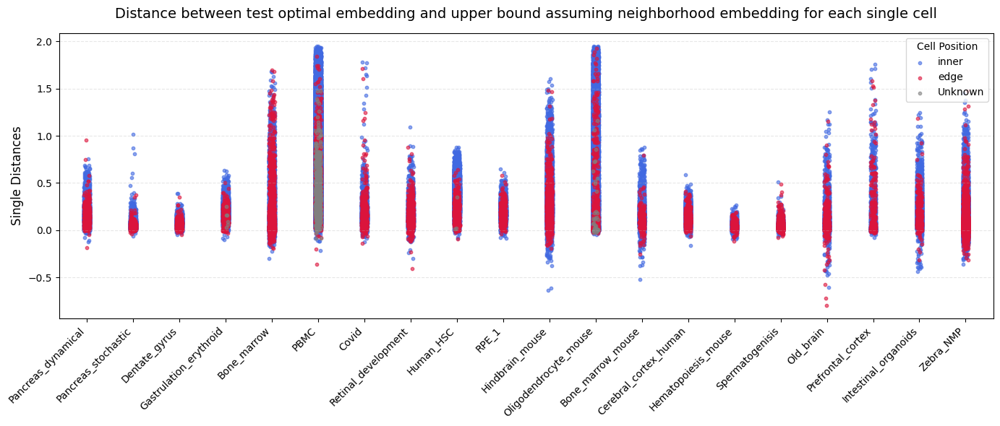

In [7]:
fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

# Define the colors for each category
color_map = {
    "inner": "royalblue",
    "edge": "crimson",
    "Unknown": "gray"
}

# Keep track of added legend items to avoid duplicating legend entries
added_to_legend = set()

for i, name in enumerate(plotset.keys()):
    x_base = i
    y_values = plotset[name]["distances"]
    labels = plotset[name]["labels"]
    x_jittered = add_jitter(x_base, y_values)
    
    # Plot each category separately to apply the correct color
    for category, color in color_map.items():
        mask = (labels == category)
        
        if np.any(mask):
            # Only add the category to the legend the very first time it appears
            legend_label = category if category not in added_to_legend else "_nolegend_"
            added_to_legend.add(category)
            
            ax.scatter(
                x_jittered[mask], 
                y_values[mask], 
                s=10, 
                alpha=0.6, 
                color=color, 
                label=legend_label
            )

ax.set_xticks(range(len(plotset)))
ax.set_xticklabels(list(plotset.keys()), rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(plotset) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Single Distances", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding for each single cell", fontsize=14, pad=15)

# Add the legend to display the color mapping
ax.legend(title="Cell Position", loc="upper right")

plt.tight_layout()
plt.show()

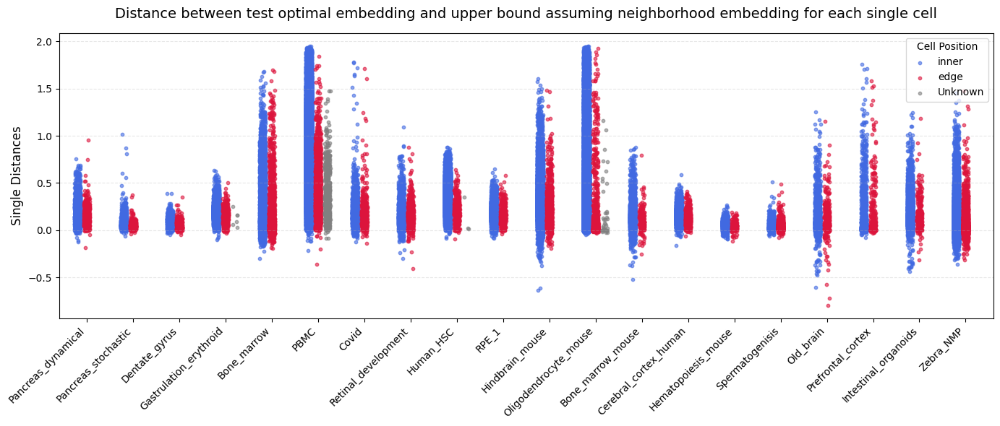

In [8]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

# Define the colors for each category
color_map = {
    "inner": "royalblue",
    "edge": "crimson",
    "Unknown": "gray"
}

# Define the horizontal offset for each category to place them side-by-side
offset_map = {
    "inner": -0.2,
    "edge": 0.0,
    "Unknown": 0.2
}

# Keep track of added legend items to avoid duplicating legend entries
added_to_legend = set()

for i, name in enumerate(plotset.keys()):
    # Convert to numpy arrays in case they are lists, to allow boolean masking
    y_values = np.array(plotset[name]["distances"])
    labels = np.array(plotset[name]["labels"])
    
    # Plot each category separately to apply the correct color and offset
    for category, color in color_map.items():
        mask = (labels == category)
        
        if np.any(mask):
            # Calculate the shifted x position for this specific category
            x_base_cat = i + offset_map[category]
            
            # Apply jitter only to the points belonging to this category
            category_y_values = y_values[mask]
            x_jittered = add_jitter(x_base_cat, category_y_values)
            
            # Only add the category to the legend the very first time it appears
            legend_label = category if category not in added_to_legend else "_nolegend_"
            added_to_legend.add(category)
            
            ax.scatter(
                x_jittered, 
                category_y_values, 
                s=10, 
                alpha=0.6, 
                color=color, 
                label=legend_label
            )

# Keep the x-ticks centered on the original group indices
ax.set_xticks(range(len(plotset)))
ax.set_xticklabels(list(plotset.keys()), rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(plotset) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Single Distances", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding for each single cell", fontsize=14, pad=15)

# Add the legend to display the color mapping
ax.legend(title="Cell Position", loc="upper right")

plt.tight_layout()
plt.show()

### Figure out which cells are at the rim of an embedding

inner    2246
rim       928
edge      522
Name: count, dtype: int64


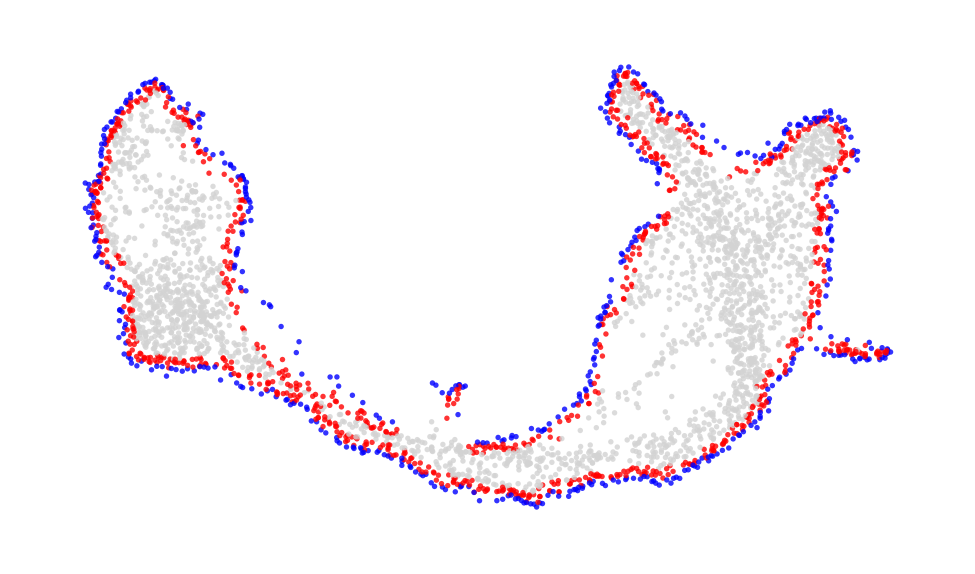

inner    2248
rim       930
edge      518
Name: count, dtype: int64


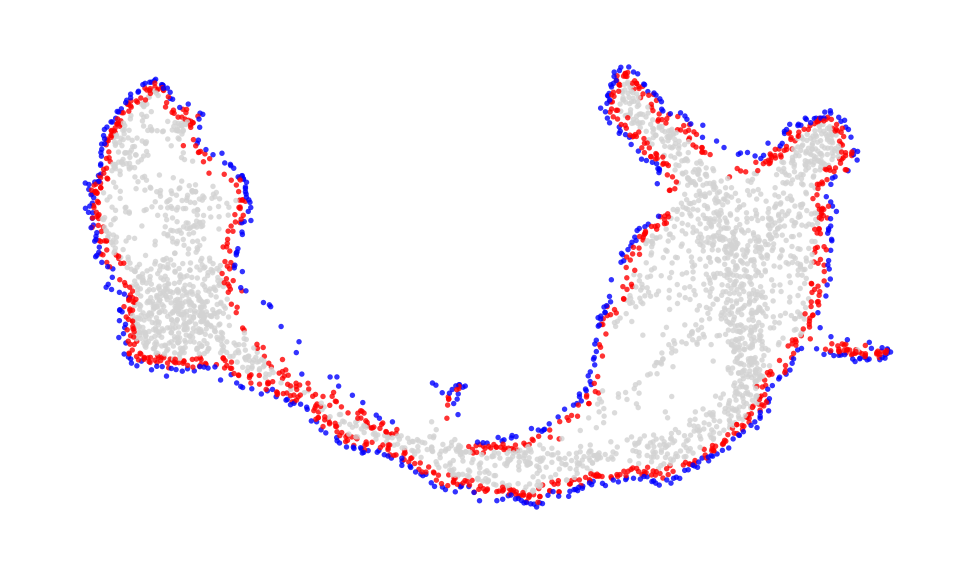

inner    1778
rim       688
edge      464
Name: count, dtype: int64


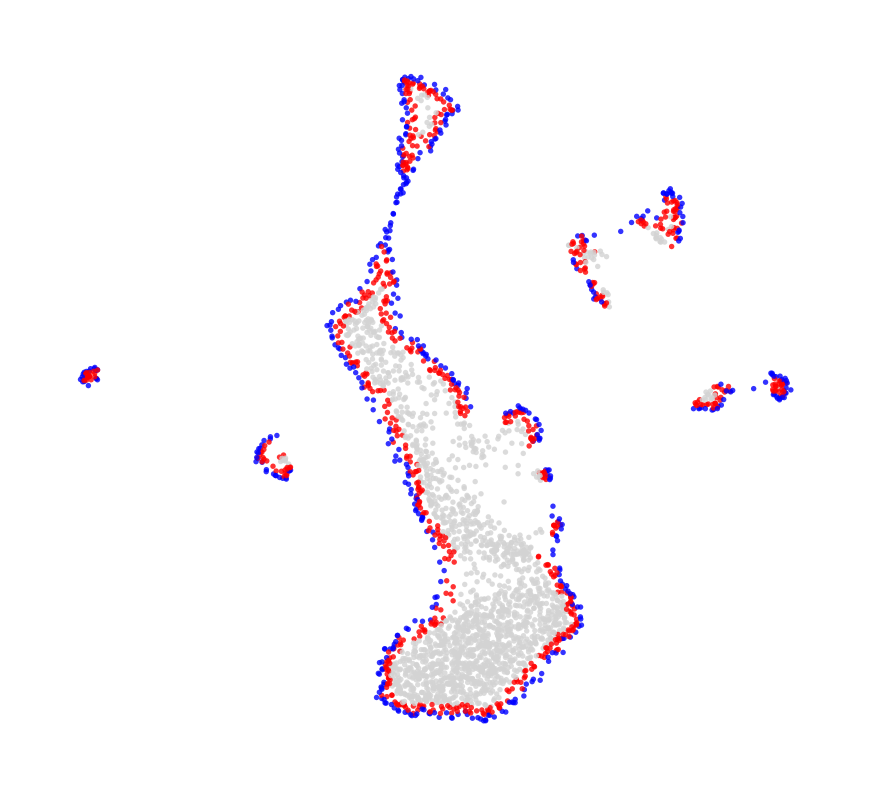

inner    8143
rim      1169
edge      503
Name: count, dtype: int64


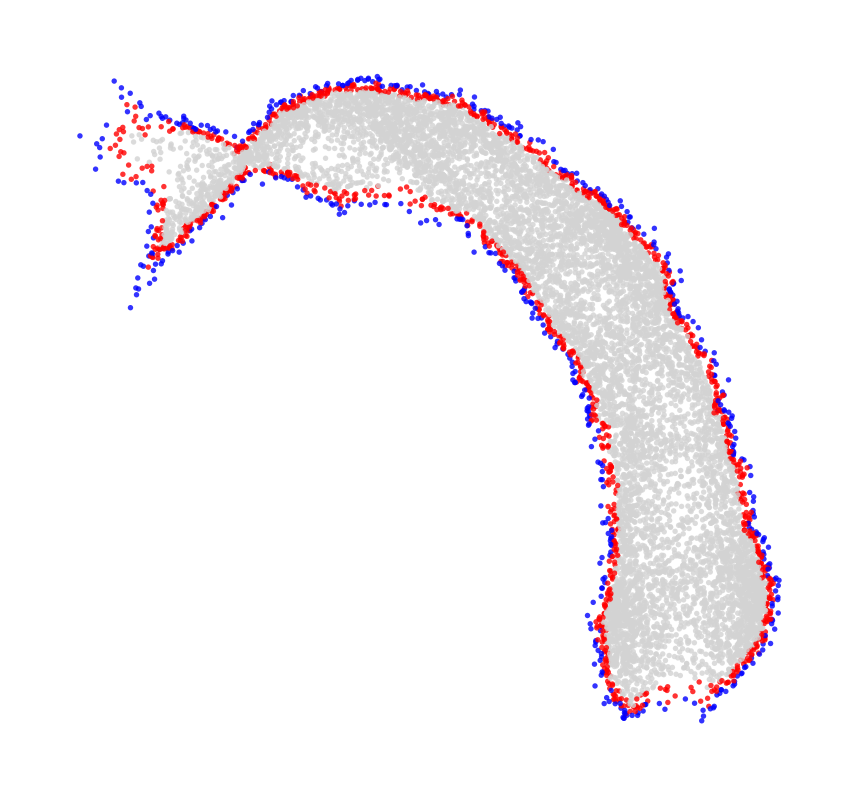

inner    2416
rim      1835
edge     1529
Name: count, dtype: int64


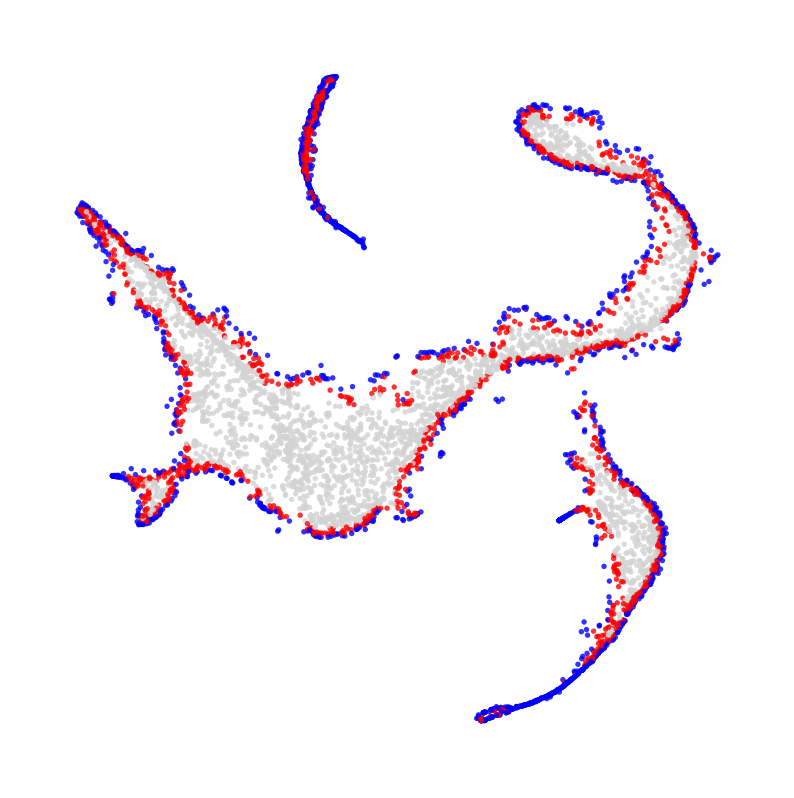

inner    59657
rim       3835
edge      2385
Name: count, dtype: int64


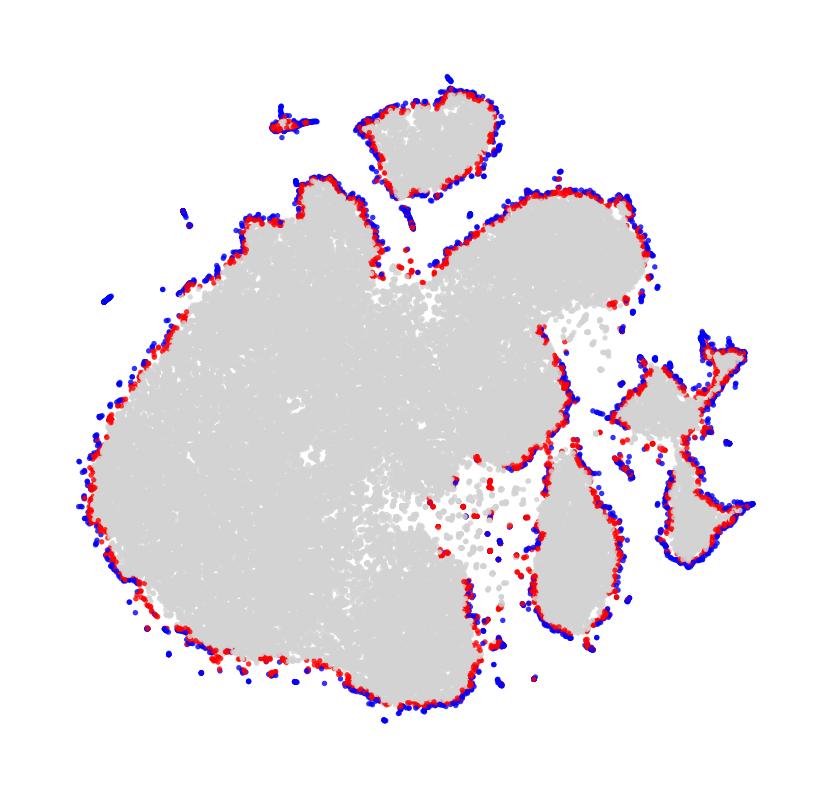

inner    1666
rim       845
edge      565
Name: count, dtype: int64


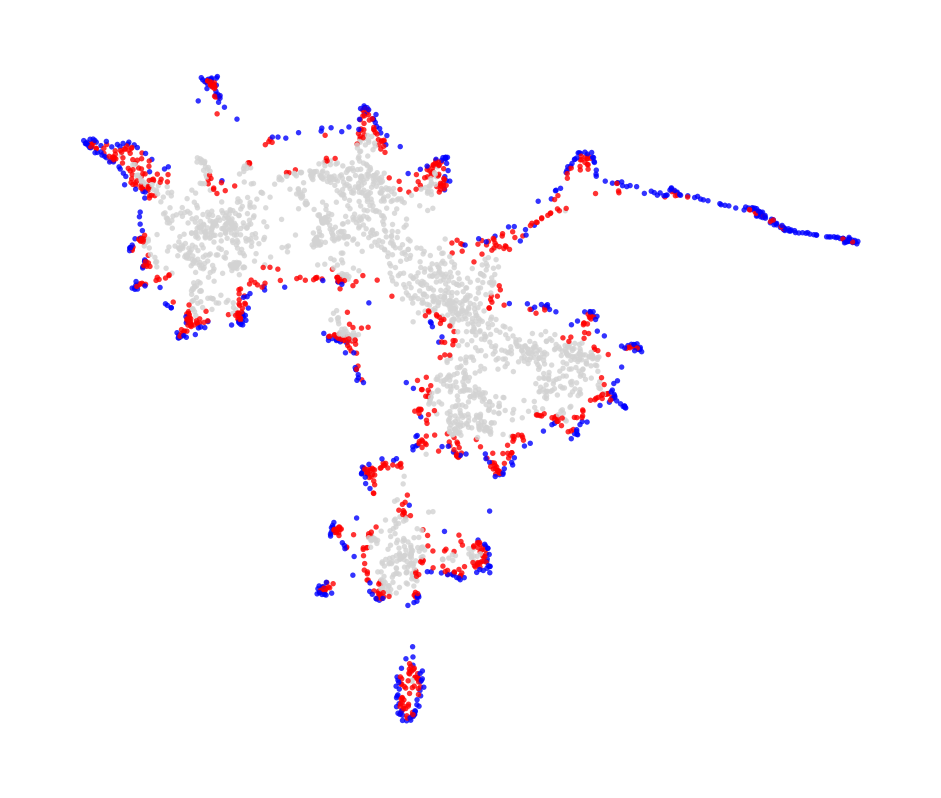

inner    1075
rim       977
edge      674
Name: count, dtype: int64


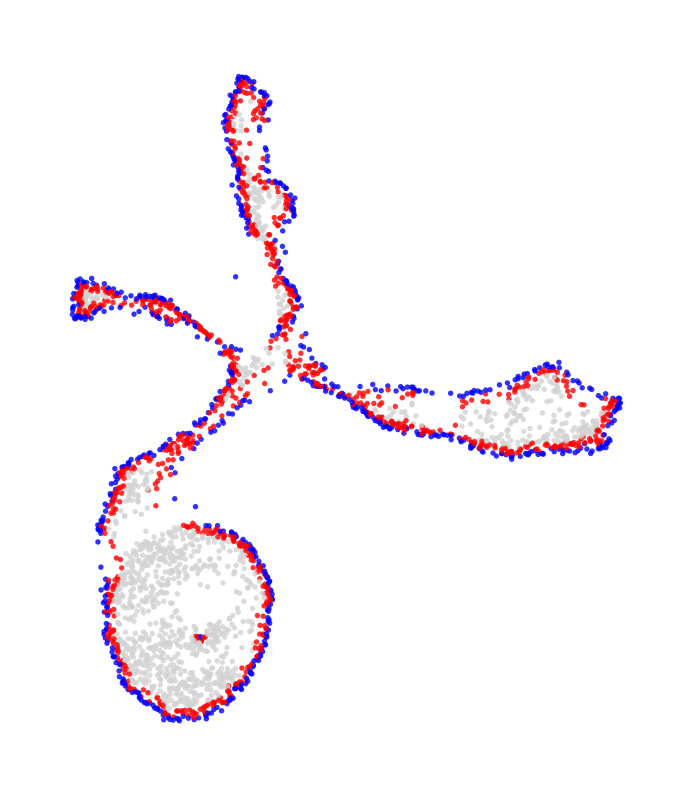

inner    10166
rim        957
edge       482
Name: count, dtype: int64


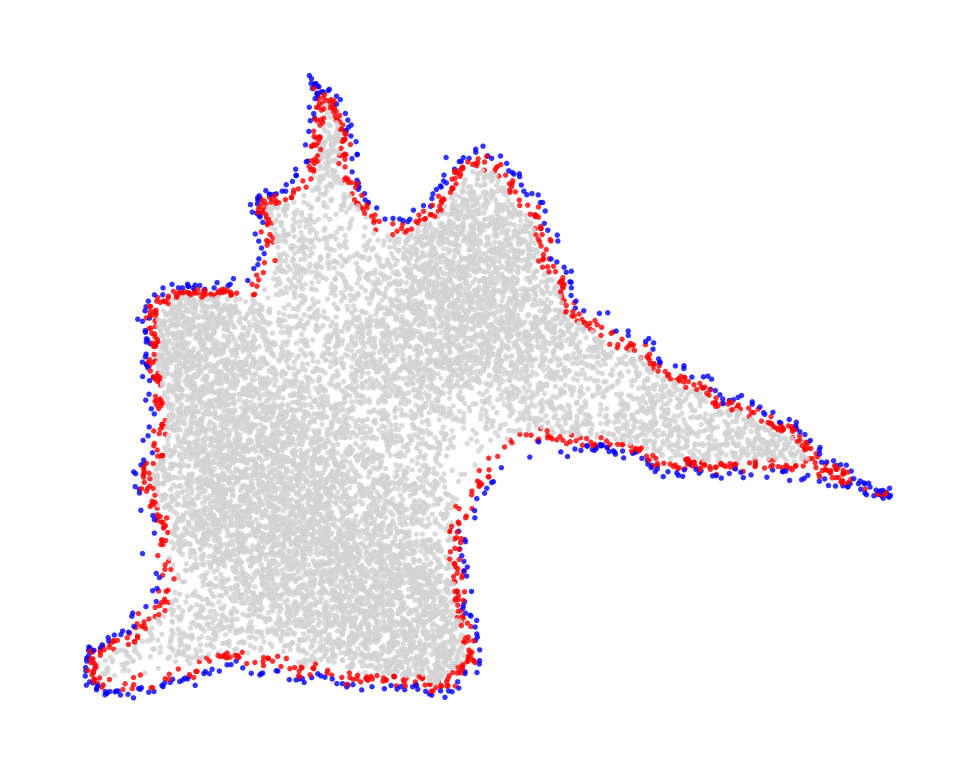

inner    4312
rim       728
edge      382
Name: count, dtype: int64


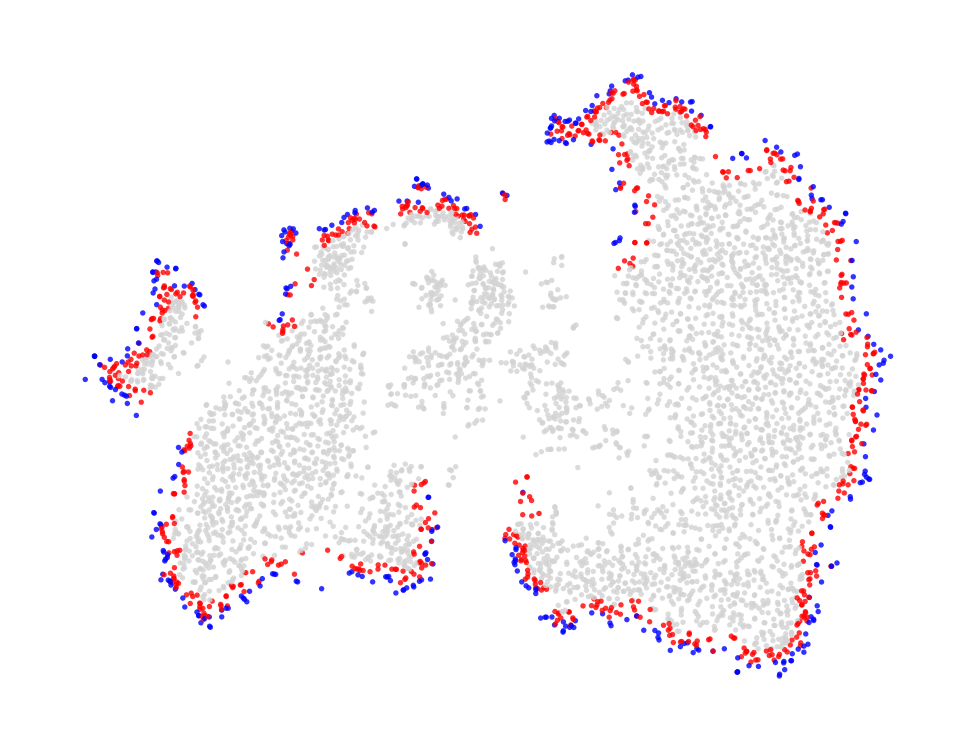

inner    10284
rim       2074
edge      1143
Name: count, dtype: int64


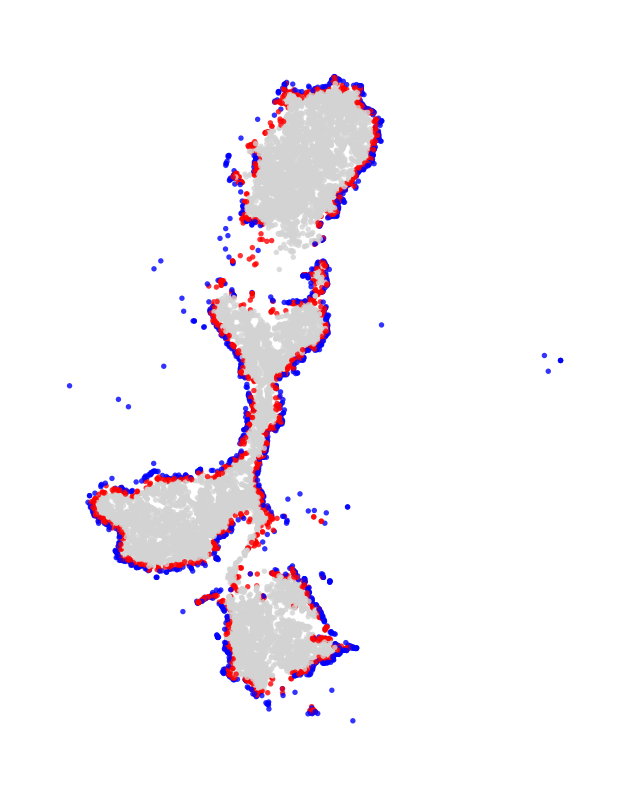

inner    33585
rim       1654
edge       907
Name: count, dtype: int64


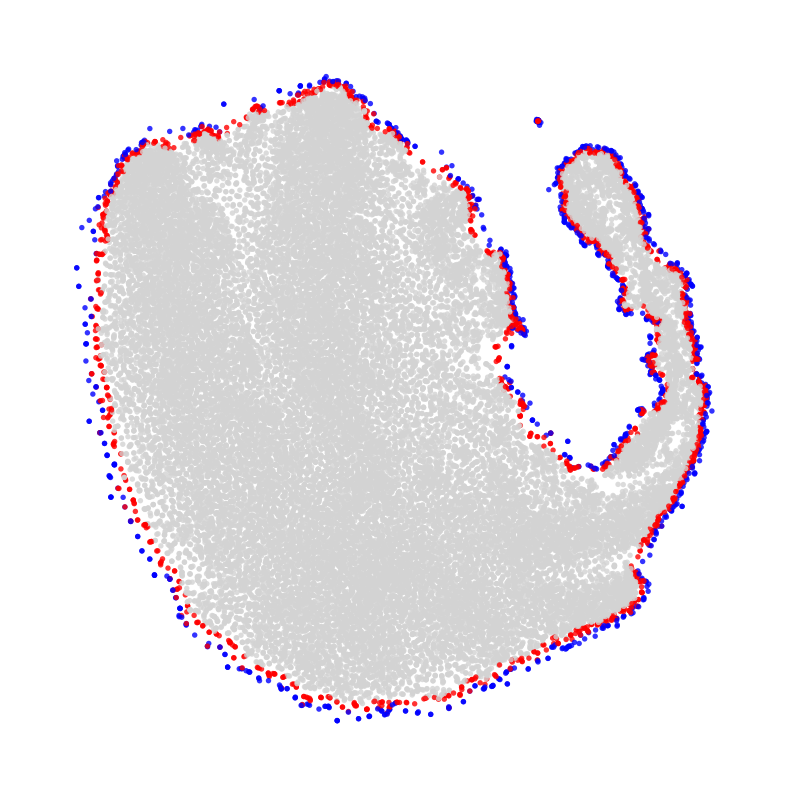

inner    1875
rim       503
edge      222
Name: count, dtype: int64


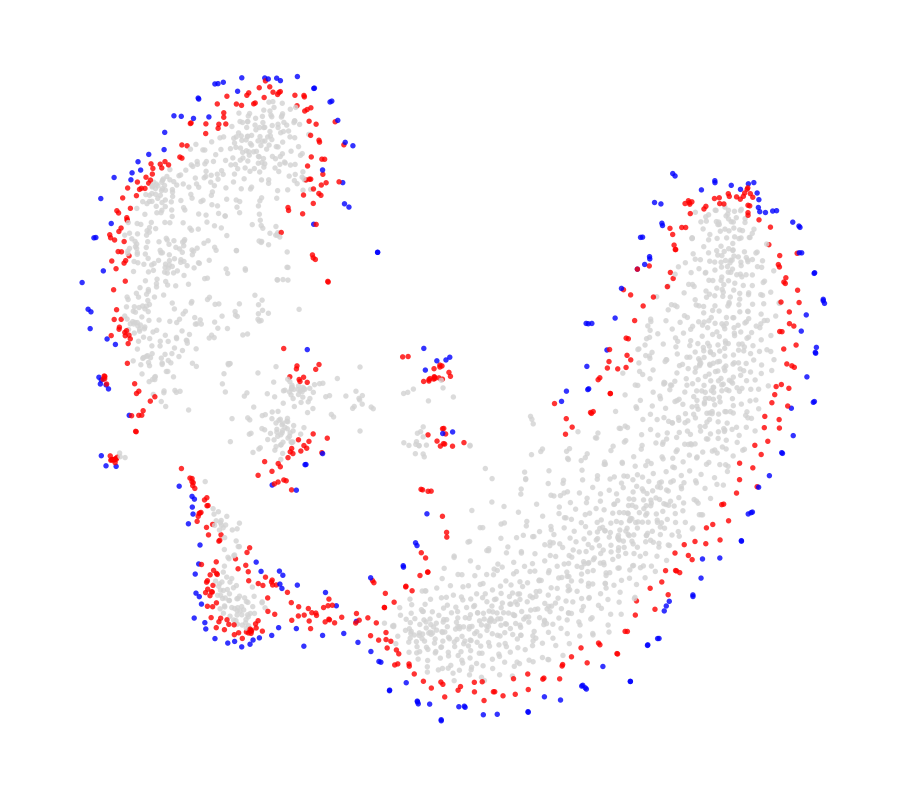

inner    3073
rim      1087
edge      533
Name: count, dtype: int64


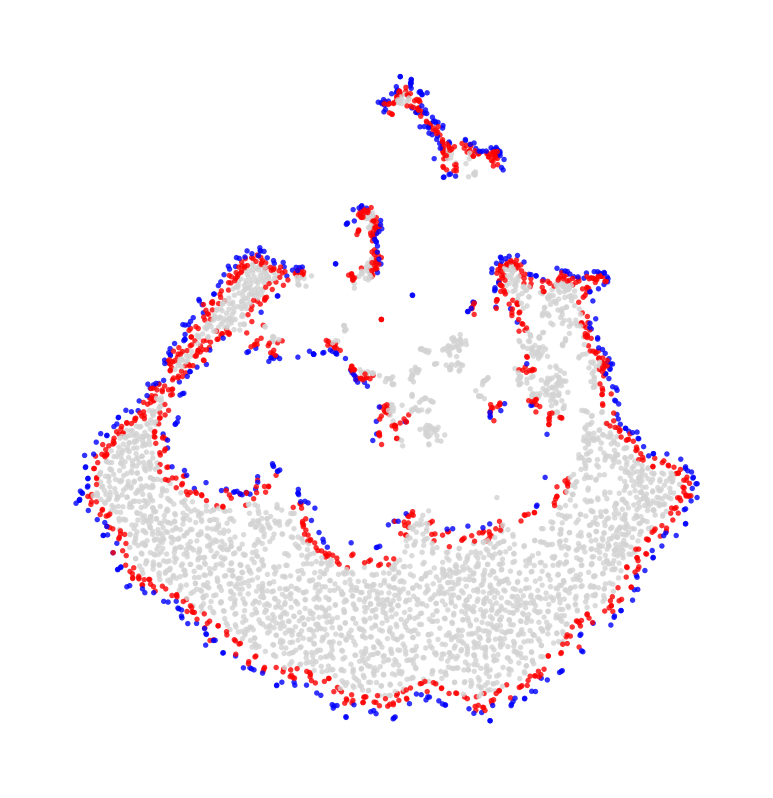

inner    1204
rim       361
edge      207
Name: count, dtype: int64


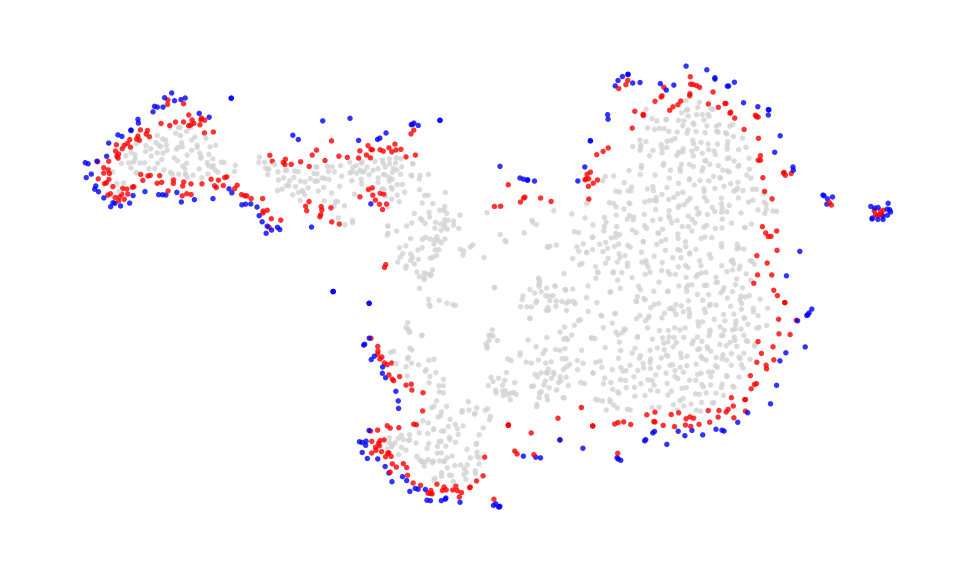

edge     878
rim      717
inner    234
Name: count, dtype: int64


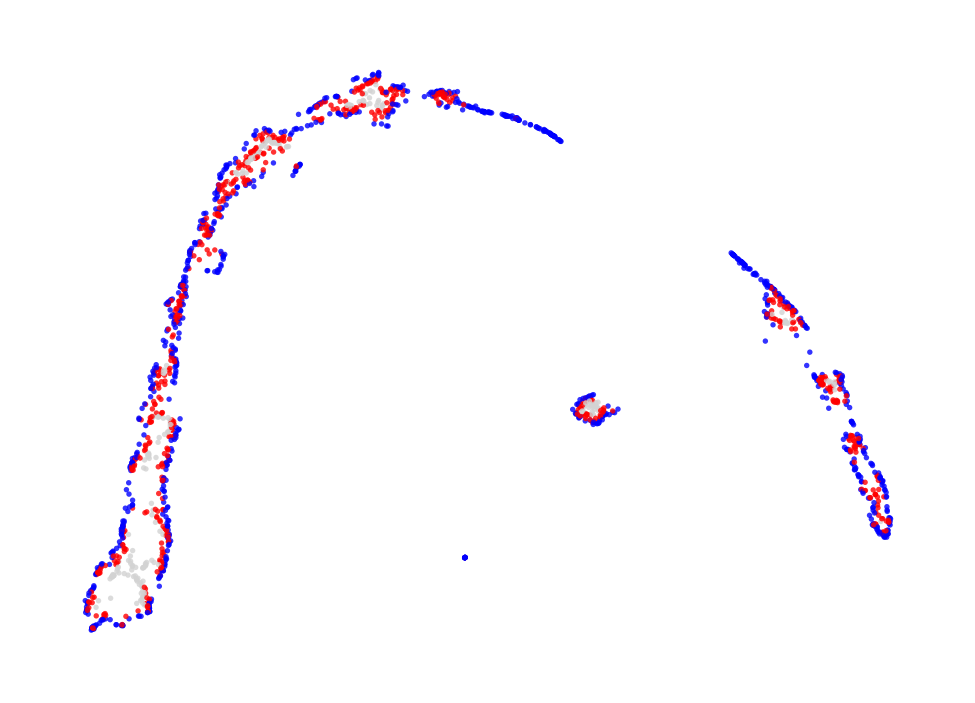

inner    749
rim      674
edge     400
Name: count, dtype: int64


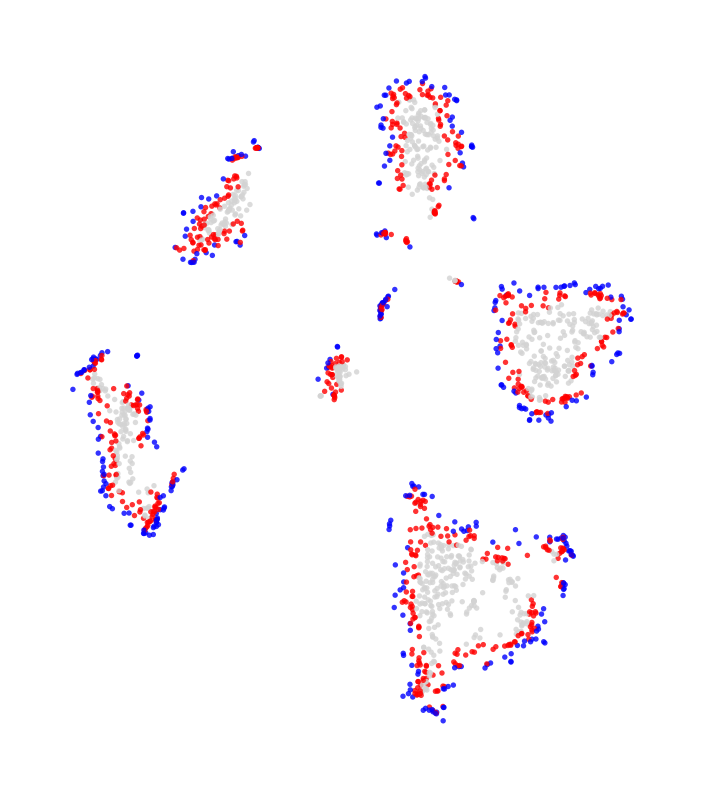

rim      471
inner    454
edge     342
Name: count, dtype: int64


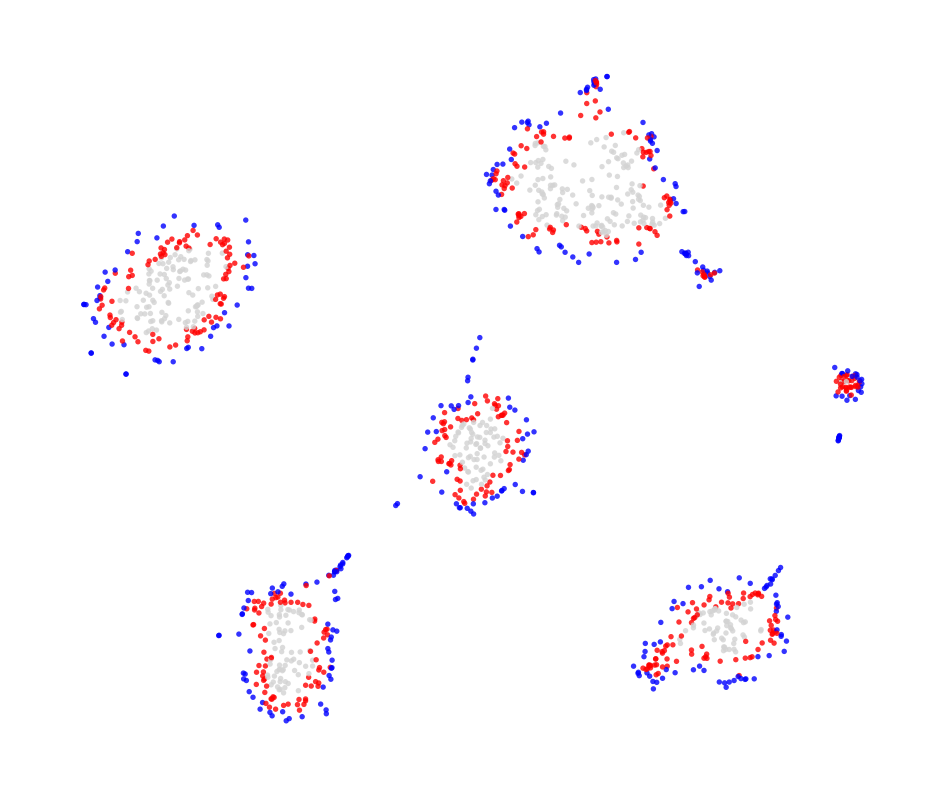

inner    3056
rim       494
edge      281
Name: count, dtype: int64


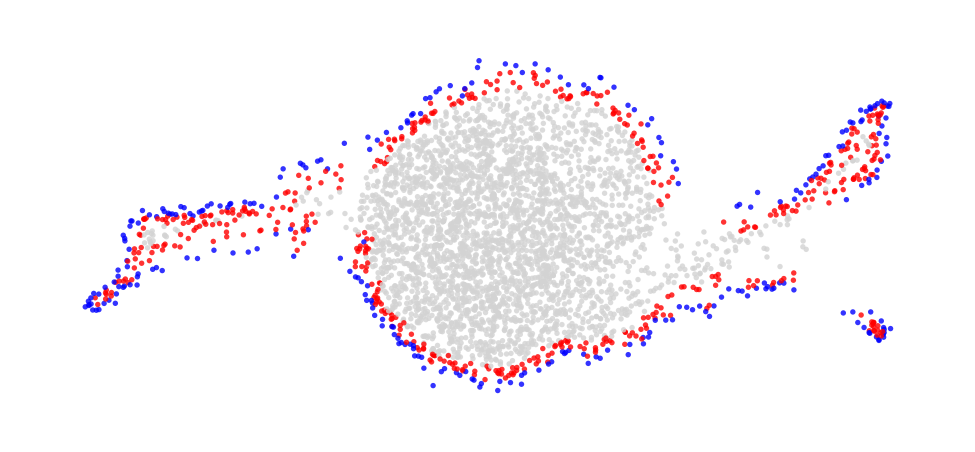

inner    9984
rim      3776
edge     2275
Name: count, dtype: int64


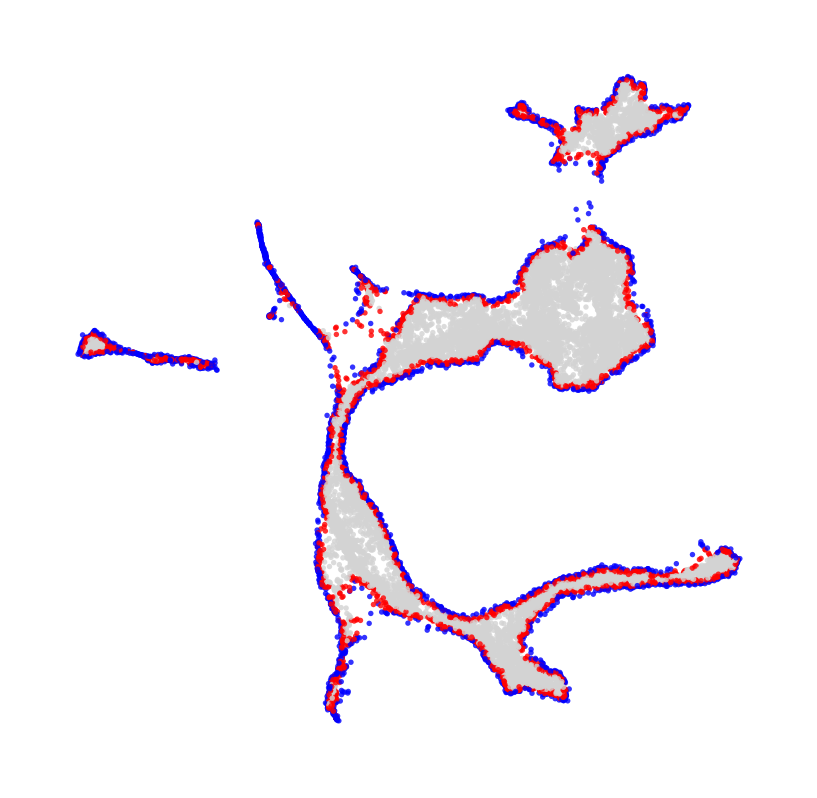

In [21]:
plotset_rim = {}
for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)
    # Extract data and parameters from the config
    adata = sc.read(config["path"]) 
    basis = config["basis"]
    clusters = config["cluster"]
    cluster_colors = config["cluster_colors"]
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    non_empty_indices = adata.uns['non_empty_indices']
    upper_n = upper[non_empty_indices]
    border_cells = adata.obs["boarder"]


    # Determine cell positions based on the gaps in the angular domain
    rim_position = ["inner"] * len(border_cells)
    
    all_nn_indices = find_neighbors(adata.obsm[f"X_{basis}"], k_neighbors=10)

    # 2. Use enumerate for cleaner, more Pythonic iteration
    for i, cell_status in enumerate(border_cells):
        if cell_status in {"edge", "Unknown"}:
            
            # 1. Mark the cell itself 
            rim_position[i] = "edge" # (Change to "rim" if you don't want to distinguish them)
            
            # 2. Mark its neighbors as "rim"
            for neighbor_idx in all_nn_indices[i]:
                # Crucial check: Only mark as 'rim' if the neighbor isn't ALSO an edge cell.
                # This prevents an edge cell from being downgraded to a rim cell just because 
                # it sits next to another edge cell.
                if border_cells[neighbor_idx] not in {"edge", "Unknown"}:
                    rim_position[neighbor_idx] = "rim"
       
    # Print results and save labels to adata.obs
    
    print(pd.Series(rim_position).value_counts())
    adata.obs["rim"] = rim_position
    adata.write_h5ad(config['path'])
    labels = adata.obs["rim"].values[non_empty_indices]
    distances = np.subtract(upper_n, best)
        
    # Store both distances and labels
    plotset_rim[name] = {
        "distances": distances,
        "labels": labels
    }

    # Plot accoridng to the new labels to check if the cells are indeed on the edge or not
    cm = 1 / 2.54 
    figsize=(5 * cm, 4 * cm)
    fig, ax = plt.subplots(dpi=450, figsize=figsize)
    ax.set(xticks=[], yticks=[])
    pl = scvelo.pl.scatter(adata, 
                                    basis=basis, 
                                    color='rim', 
                                    palette={'rim': 'red', 'inner': 'lightgrey', 'edge': 'blue', 'Unknown': 'orange'},
                                    show=False, size=3,rasterized=True, figsize=figsize,alpha=0.8,
                                    ax=ax, frameon=False, xlabel='', ylabel='', title ='', legend_loc='none')
    ax.set_aspect('equal')
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    pl.set_rasterized(True)
    plt.savefig(f"/mnt/volume/Johanna_Velotest/results/bounds/{name}_highlighted_edges.pdf", transparent=True, dpi=450)
    plt.show()

In [13]:
plotset_rim = {}
records = []
for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)
    adata = sc.read(config["path"]) 


    upper = adata.obsm['upper_max_neighbors'] 
    best = adata.uns['best_embedding']
    non_empty_indices = adata.uns['non_empty_indices']
    upper_n = upper[non_empty_indices]
    distances = np.subtract(upper_n, best)

    labels = adata.obs["rim"].values[non_empty_indices]

    plotset_rim[name] = {
            "distances": distances,
            "labels": labels
        }     

    for dist, lbl in zip(distances, labels):
        records.append({
            "Dataset": name,
            "Distance": dist,
            "Label": lbl
        })

df = pd.DataFrame(records)
df.to_csv("/mnt/volume/Johanna_Velotest/results/bounds/Rim_plot.csv")


In [11]:
print(plotset_rim)
df.to_pickle("/mnt/volume/Johanna_Velotest/results/bounds/Rim_plot.pkl")

{'Pancreas_dynamical': {'distances': array([0.17283934, 0.11826972, 0.12507147, ..., 0.25135127, 0.01989639,
       0.10833305], shape=(3646,), dtype=float32), 'labels': ['inner', 'inner', 'rim', 'inner', 'edge', ..., 'inner', 'inner', 'inner', 'edge', 'inner']
Length: 3646
Categories (3, object): ['edge', 'inner', 'rim']}, 'Pancreas_stochastic': {'distances': array([0.08695696, 0.10990676, 0.02626085, ..., 0.07169084, 0.0579117 ,
       0.01395593], shape=(3676,), dtype=float32), 'labels': ['inner', 'inner', 'rim', 'inner', 'edge', ..., 'inner', 'inner', 'inner', 'edge', 'inner']
Length: 3676
Categories (3, object): ['edge', 'inner', 'rim']}, 'Dentate_gyrus': {'distances': array([8.8805966e-02, 6.2044635e-03, 7.4779123e-02, ..., 8.9406967e-08,
       5.9831813e-02, 9.4229847e-02], shape=(2888,), dtype=float32), 'labels': ['inner', 'edge', 'edge', 'rim', 'inner', ..., 'rim', 'inner', 'edge', 'inner', 'inner']
Length: 2888
Categories (3, object): ['edge', 'inner', 'rim']}, 'Gastrulation

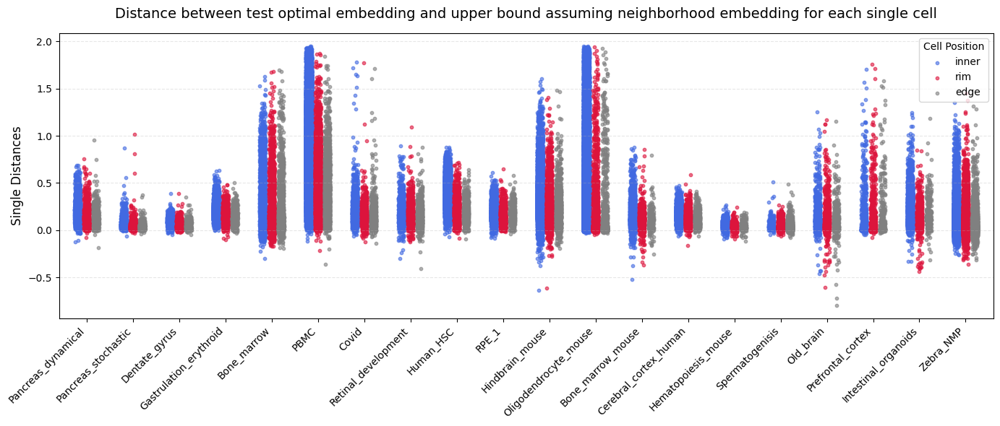

In [6]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

# Define the colors for each category
color_map = {
    "inner": "royalblue",
    "rim": "crimson",
    "edge": "gray"
}

# Define the horizontal offset for each category to place them side-by-side
offset_map = {
    "inner": -0.2,
    "rim": 0.0,
    "edge": 0.2
}

# Keep track of added legend items to avoid duplicating legend entries
added_to_legend = set()

for i, name in enumerate(plotset_rim.keys()):
    # Convert to numpy arrays in case they are lists, to allow boolean masking
    y_values = np.array(plotset_rim[name]["distances"])
    labels = np.array(plotset_rim[name]["labels"])
    
    # Plot each category separately to apply the correct color and offset
    for category, color in color_map.items():
        mask = (labels == category)
        
        if np.any(mask):
            # Calculate the shifted x position for this specific category
            x_base_cat = i + offset_map[category]
            
            # Apply jitter only to the points belonging to this category
            category_y_values = y_values[mask]
            x_jittered = add_jitter(x_base_cat, category_y_values)
            
            # Only add the category to the legend the very first time it appears
            legend_label = category if category not in added_to_legend else "_nolegend_"
            added_to_legend.add(category)
            
            ax.scatter(
                x_jittered, 
                category_y_values, 
                s=10, 
                alpha=0.6, 
                color=color, 
                label=legend_label
            )

# Keep the x-ticks centered on the original group indices
ax.set_xticks(range(len(plotset_rim)))
ax.set_xticklabels(list(plotset_rim.keys()), rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(plotset_rim) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Single Distances", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding for each single cell", fontsize=14, pad=15)

# Add the legend to display the color mapping
ax.legend(title="Cell Position", loc="upper right")

plt.tight_layout()
plt.show()

In [37]:
responses = {}
features = {}
scores = {}
importance = pd.DataFrame()
for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)
    print(name)
    # Collect data information
    adata = sc.read(config['path'])
    basis = config['basis']
    neighbors = config['number_neighbors_to_sample_from']
    cluster = config['cluster']
    color = config['cluster_colors']

    upper = adata.obsm['upper_max_neighbors']
    best = adata.uns['best_embedding']
    non_empty_indices = adata.uns['non_empty_indices']
    # Copy dataset for only the cells that have a value
    adata_copy = adata[non_empty_indices, :].copy()
    upper = upper[non_empty_indices]
    distances = np.subtract(upper,best)

    X, features = prepare_rim_matrix(adata_copy, cluster=cluster, basis=basis)
    response = prepare_classification(distances)

    pipe = Pipeline([('scaler', preprocessing.StandardScaler()), ('clf', ensemble.RandomForestClassifier(random_state=0, n_estimators=100))])
    cv = cross_validate(pipe, X, response, cv=5, return_estimator=True)
    fold_importances = [pipeline.named_steps['clf'].feature_importances_ for pipeline in cv['estimator']]
    mean_importance = np.mean(fold_importances, axis=0)
    current_df = pd.DataFrame({
        'Feature': features,
        name : mean_importance
    })
    if importance.empty:
        importance = current_df
    else:
        importance = importance.merge(current_df, on='Feature', how='outer')

    scores[name] = cv['test_score']
    responses[name] = response
    np.savez_compressed(f"/mnt/volume/Johanna_Velotest/results/ml_within/RF_6feature_{name}.npz", 
                    X=X, 
                    response=response, 
                    features=features)

df_scores = pd.DataFrame(scores)
print(importance)
print(df_scores.mean())


Pancreas_dynamical
Pancreas_stochastic
Dentate_gyrus
Gastrulation_erythroid
Bone_marrow
PBMC
Covid
Retinal_development
Human_HSC
RPE_1
Hindbrain_mouse
Oligodendrocyte_mouse
Bone_marrow_mouse
Hematopoiesis_mouse
Spermatogenisis
Old_brain
Prefrontal_cortex
Zebra_NMP
           Feature  Pancreas_dynamical  Pancreas_stochastic  Dentate_gyrus  \
0       confidence            0.206586             0.192217       0.173380   
1   highD_velocity            0.160753             0.199263       0.229018   
2    num_neighbors            0.142650             0.131951       0.129364   
3    position_edge            0.007646             0.009433       0.008654   
4   position_inner            0.028362             0.030948       0.053140   
5     position_rim            0.011513             0.010891       0.013847   
6         ratio_su            0.142912             0.132501       0.131931   
7    total_spliced            0.143404             0.145785       0.135690   
8  total_unspliced            0.1